In [1]:
# ============================================================
# Imports and environment setup
# ============================================================

# Standard library
import copy
import hashlib
import importlib
import itertools
import json
import random
import time

from pathlib import Path
from time import perf_counter

# Numerical computing and data handling
import numpy as np

# Legacy FEniCS can silently replace NumPy 2 fields with zeros.
if int(np.__version__.split(".")[0]) >= 2:
    raise RuntimeError(
        "Select the U-bolt (NumPy 1.26) kernel, restart it, and run all cells. "
        f"Current NumPy version: {np.__version__}"
    )

import pandas as pd
from scipy.stats import pearsonr

# Machine learning
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Visualization
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import Image, display, clear_output

# Excel utilities
from openpyxl import load_workbook
from openpyxl.utils import get_column_letter

# Finite element utilities
import dlroms
import dlroms.fespaces as fe
from dlroms.fespaces import gifs

# Custom support functions
%load_ext autoreload
%autoreload 0

import support_functions as sf

# Device selection
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"PyTorch device: {device}")

PyTorch device: cpu


# Assignment 2 — U-Bolt Damage Propagation

**Non-intrusive model order reduction using Proper Orthogonal Decomposition and Neural Networks (POD-NN)**

This notebook constructs and evaluates a data-driven surrogate for the transient Fisher–KPP damage-propagation model. It focuses on the forward map $(\boldsymbol\mu,t)\mapsto u_h(\boldsymbol\mu,t)$; parameter identification and temporal extrapolation are addressed separately.

## 1. Problem Setup and Dataset


### 1.1 Physical Problem and Governing Equations

This assignment investigates the propagation of micro-damage in a two-dimensional U-bolt domain $\Omega \subset \mathbb{R}^2$. The damage field $u(\mathbf{x},t)\in[0,1]$ is governed by the nonlinear Fisher–Kolmogorov–Petrovsky–Piskunov (Fisher-KPP) reaction-diffusion equation:

$$
\begin{cases}
\displaystyle \frac{\partial u}{\partial t}-D\Delta u=ru(1-u),
& \text{in }\Omega\times(0,T],\\[4pt]
\nabla u\cdot\mathbf{n}=0,
& \text{on }\partial\Omega\times(0,T],\\[4pt]
u(\mathbf{x},0)=g_\delta(\mathbf{x}),
& \text{in }\Omega.
\end{cases}
$$

The diffusion coefficient $D$ controls the spatial spreading of damage, while the reaction coefficient $r$ governs its local growth. The initial damage distribution is defined as

$$
g_\delta(x,y)=
\begin{cases}
1, & |x-\delta|<0.1 \text{ and } y\geq4,\\
0, & \text{otherwise}.
\end{cases}
$$

The physical parameters are expressed in terms of three normalized variables $\boldsymbol{\mu}\in[0,1]^3$:

$$
D=10^{\mu_1},\qquad
r=10^{\mu_2+2},\qquad
\delta=\mu_3+1.
$$

The solution is simulated over $T=0.02$ s. A Finite Element Method (FEM) discretization produces a high-dimensional approximation $\mathbf{u}_h(\boldsymbol{\mu},t)\in\mathbb{R}^{N_h}$.

**Reduced-order modeling strategy.** The objective is to construct a non-intrusive surrogate for the parameter-to-solution map

$$
(\boldsymbol{\mu},t)\longmapsto\mathbf{u}_h(\boldsymbol{\mu},t).
$$

The nonlinear reaction term makes a standard POD-Galerkin approach more computationally demanding, since evaluating the reduced nonlinear residual generally retains a dependence on the full-order dimension unless additional hyper-reduction techniques are introduced.

We therefore adopt a **POD-NN approach**: Proper Orthogonal Decomposition identifies a low-dimensional linear space from the FOM snapshots, while a neural network learns the dependence of the corresponding reduced coefficients on the parameters and time. This avoids solving a reduced dynamical system during online inference.



### 1.2 Dataset Description and Preprocessing

The provided dataset contains $N_{\mathrm{traj}}=100$ independent FOM trajectories, generated by uniformly sampling the normalized parameter domain $[0,1]^3$.

Each trajectory consists of $N_t=41$ equally spaced temporal snapshots, with $\Delta t=5\times10^{-4}$ s, and each snapshot contains $N_h=6636$ spatial degrees of freedom.

The dataset is organized into two arrays:

- `mu`: parameter configurations, with shape $(N_{\mathrm{traj}},3)$.
- `u`: FOM solutions, with shape $(N_{\mathrm{traj}},N_t,N_h)$.

The temporal grid is reconstructed from the prescribed time step. Subsequently, the training trajectories will be reshaped into a snapshot matrix, with one row per parameter-time pair, for the construction of the POD basis.


In [2]:
# Load the precomputed FOM dataset
with np.load("u-bolt.npz") as data:
    mu = data["mu"]
    u = data["u"]

# Dataset dimensions
N_traj, N_t, N_h = u.shape
N_params = mu.shape[1]

# Time discretization
dt = 5e-4
t = np.arange(N_t) * dt
T = t[-1]

# Consistency checks
assert mu.shape == (N_traj, 3)
assert N_traj == 100
assert N_t == 41
assert N_h == 6636
assert np.all((mu >= 0) & (mu <= 1))

print(f"FOM trajectories : {N_traj}")
print(f"Parameters       : {N_params}")
print(f"Time snapshots   : {N_t}")
print(f"Spatial DOFs     : {N_h}")
print(f"Total snapshots  : {N_traj * N_t}")
print(f"Time interval    : [0, {T:.4f}] s")
print(f"Time step        : {dt:.4g} s")


FOM trajectories : 100
Parameters       : 3
Time snapshots   : 41
Spatial DOFs     : 6636
Total snapshots  : 4100
Time interval    : [0, 0.0200] s
Time step        : 0.0005 s



### 1.3 Training, Validation and Test Split

The dataset is partitioned into **60 training, 15 validation and 25 test trajectories**, preserving the 75/25 split required by the assignment.

The three subsets serve different purposes:

- **Training:** construction of the POD basis, computation of normalization statistics and optimization of the neural network.
- **Validation:** selection of the POD dimension, neural network hyperparameters and model checkpoint.
- **Test:** final evaluation of the selected surrogate on unseen trajectories.

The partition is performed **at the trajectory level**, before reshaping the solutions into individual snapshots. This prevents temporal snapshots belonging to the same FOM simulation from appearing in different subsets, which would introduce data leakage.

A fixed random seed ensures reproducibility. The resulting parameter distributions are subsequently examined to assess their representativeness.


In [3]:
# Reproducible trajectory-level split
indices = np.random.default_rng(115).permutation(N_traj)

train_idx = indices[:60]
val_idx = indices[60:75]
test_idx = indices[75:]

mu_train, u_train = mu[train_idx], u[train_idx]
mu_val, u_val = mu[val_idx], u[val_idx]
mu_test, u_test = mu[test_idx], u[test_idx]

# POD snapshot matrix: training data only
N_train = len(train_idx)
snapshots_train = u_train.reshape(-1, N_h)

# Verify disjoint trajectories
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print(f"Training   : {len(train_idx)} trajectories")
print(f"Validation : {len(val_idx)} trajectories")
print(f"Test       : {len(test_idx)} trajectories")
print(f"Training snapshot matrix: {snapshots_train.shape}")


Training   : 60 trajectories
Validation : 15 trajectories
Test       : 25 trajectories
Training snapshot matrix: (2460, 6636)



#### 1.3.1 Parameter-Space Representativeness

The quality of the data partition is assessed through two complementary criteria:

**Marginal distribution balance.** For each parameter, differences between the validation/test subsets and the training set are quantified using the normalized mean shift and standard deviation ratio:

$$
\mathrm{MeanShift}_j =
\frac{|\bar{\mu}_{j,\mathrm{split}}-\bar{\mu}_{j,\mathrm{train}}|}
{\sigma_{j,\mathrm{train}}},
\qquad
\mathrm{StdRatio}_j =
\frac{\sigma_{j,\mathrm{split}}}
{\sigma_{j,\mathrm{train}}}.
$$

**Joint parameter-space coverage.** The Euclidean distance to the nearest training sample measures the local proximity of validation and test configurations to the training set. Convex-hull membership additionally indicates whether a configuration lies within the convex region spanned by the training samples.

These diagnostics help characterize the evaluation subsets without modifying the fixed data partition.


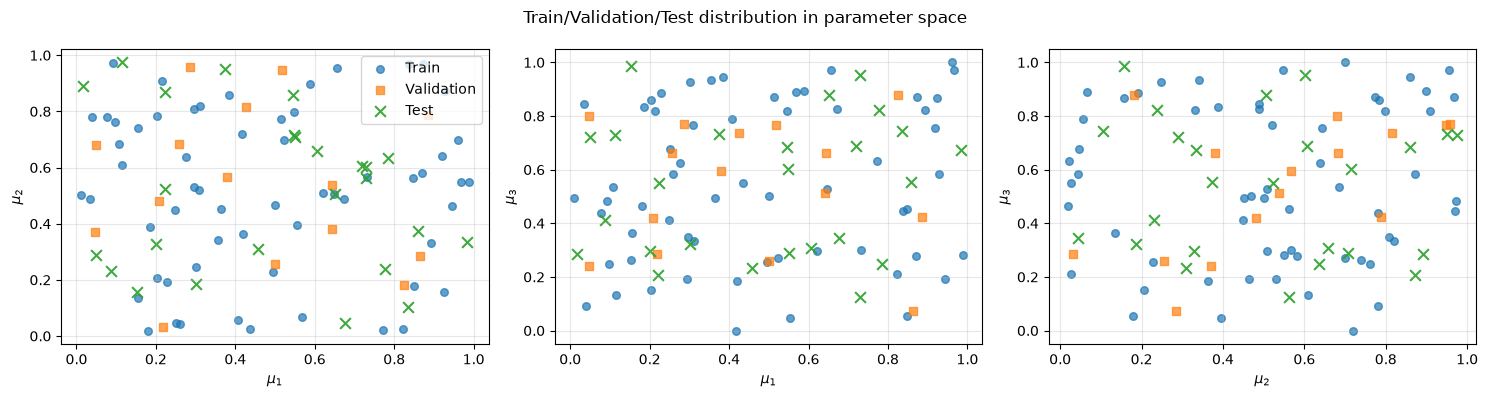

,,min,max,mean,std,mean_shift_std,std_ratio
parameter,split,,,,,,
mu_1,Train,0.010,0.989,0.474,0.296,0.000,1.000
mu_2,Train,0.019,0.972,0.513,0.286,0.000,1.000
mu_3,Train,0.000,1.000,0.543,0.290,0.000,1.000
mu_1,Validation,0.046,0.886,0.450,0.270,0.082,0.911
mu_2,Validation,0.031,0.958,0.531,0.272,0.062,0.951
mu_3,Validation,0.073,0.877,0.539,0.236,0.012,0.815
mu_1,Test,0.017,0.984,0.488,0.285,0.047,0.963
mu_2,Test,0.045,0.974,0.506,0.274,0.025,0.960
mu_3,Test,0.125,0.985,0.536,0.252,0.024,0.869


,n_trajectories,nearest_train_median,nearest_train_p90,nearest_train_max,inside_train_hull_percent,hull_status
split,,,,,,
Train,60,0.161,0.221,0.311,100.000,ok
Validation,15,0.130,0.191,0.243,66.667,ok
Test,25,0.158,0.200,0.233,72.000,ok


In [4]:
# Parameter distribution and coverage diagnostics
sf.plot_parameter_splits(mu_train, mu_val, mu_test)
plt.show()

parameter_balance, parameter_coverage = sf.diagnose_parameter_splits(
    mu_train, mu_val, mu_test
)

display(parameter_balance.round(3))
display(parameter_coverage.round(3))



**Split assessment.** The three subsets exhibit comparable marginal parameter distributions, with normalized mean shifts below $0.083$ and standard deviation ratios between $0.815$ and $0.963$.

The median nearest-training distances are $0.130$ for validation and $0.158$ for test, compared with $0.161$ for the training leave-one-out reference. Furthermore, $66.7\%$ of validation and $72.0\%$ of test configurations lie inside the training convex hull.

Overall, the split provides comparable parameter-space coverage across subsets. The configurations outside the training convex hull also allow us to investigate generalization beyond the convex region spanned by the training samples, although they remain within the original parameter domain.


## 2. Proper Orthogonal Decomposition


### 2.1 FEM Mesh and Mass Matrix

The first step in constructing the POD-NN surrogate is to identify a low-dimensional space capable of accurately representing the FOM solution trajectories.

Since the snapshots originate from a Finite Element discretization, the POD basis is constructed using the spatial $L^2(\Omega)$ inner product rather than the standard Euclidean one.

Let $\{\varphi_i\}_{i=1}^{N_h}$ denote the FEM basis functions, so that a discrete field can be written as

$$
u_h(\mathbf{x})=\sum_{i=1}^{N_h}u_i\varphi_i(\mathbf{x}).
$$

The corresponding mass matrix is defined as

$$
M_{ij}=\int_\Omega\varphi_i(\mathbf{x})\varphi_j(\mathbf{x})\,d\Omega.
$$

For two discrete fields $\mathbf{u},\mathbf{v}\in\mathbb{R}^{N_h}$, this yields

$$
\langle u_h,v_h\rangle_{L^2(\Omega)}
=\mathbf{u}^TM\mathbf{v},
\qquad
\|u_h\|_{L^2(\Omega)}
=\sqrt{\mathbf{u}^TM\mathbf{u}}.
$$

We reconstruct the original U-bolt mesh and assemble $M$ using the same spatial discretization employed to generate the dataset. Matching both the mesh and the ordering of the degrees of freedom is essential for a physically consistent POD.

The resulting mass matrix will be used consistently for POD construction, orthogonal projection and error evaluation.


In [5]:

# Reconstruct the FEM discretization
mesh, Vh = sf.build_ubolt_mesh(stepsize=0.05, knots=30)

# Verify that FEM conversion preserves the actual dataset values
sf.check_fem_conversion(u_train[0, 0], Vh)

# Assemble the FEM mass matrix
M = sf.assemble_mass_matrix(Vh)

# Dimension consistency
assert Vh.dim() == N_h
assert M.shape == (N_h, N_h)

print(f"FEM degrees of freedom: {Vh.dim()}")
print(f"Mass matrix shape: {M.shape}")


FEM degrees of freedom: 6636
Mass matrix shape: (6636, 6636)



### 2.2 POD Basis Construction and Singular Value Decay

The training trajectories are collected into the snapshot matrix

$$
S=
\begin{bmatrix}
\mathbf{u}_h(\boldsymbol{\mu}_1,t_1)^T\\
\vdots\\
\mathbf{u}_h(\boldsymbol{\mu}_{N_{\mathrm{train}}},t_{N_t})^T
\end{bmatrix}
\in\mathbb{R}^{N_s\times N_h},
\qquad
N_s=N_{\mathrm{train}}N_t.
$$

We seek an $N$-dimensional space spanned by the columns of $V_N\in\mathbb{R}^{N_h\times N}$ that minimizes the total squared projection error over the training snapshots:

$$
V_N=
\underset{V\in\mathbb{R}^{N_h\times N}}{\operatorname{argmin}}
\sum_{k=1}^{N_s}
\left\|
\mathbf{u}_h^{(k)}-VV^TM\mathbf{u}_h^{(k)}
\right\|_M^2,
\qquad
\text{subject to }V^TMV=I_N.
$$

Here, $\|\mathbf{v}\|_M^2=\mathbf{v}^TM\mathbf{v}$. The optimal subspace is obtained through an **uncentered, mass-weighted POD**, using the method of snapshots.

Rather than directly decomposing the high-dimensional snapshot matrix, we construct the correlation matrix

$$
C=SMS^T\in\mathbb{R}^{N_s\times N_s},
$$

and solve the eigenvalue problem

$$
Cq_i=\lambda_iq_i,
\qquad
\lambda_1\geq\lambda_2\geq\cdots\geq0.
$$

The corresponding POD modes are recovered as

$$
\boldsymbol{\phi}_i=
\frac{S^Tq_i}{\sqrt{\lambda_i}},
\qquad
s_i=\sqrt{\lambda_i},
$$

where $s_i$ are the mass-weighted singular values.

The resulting modes are orthonormal in the FEM $L^2$ inner product:

$$
\boldsymbol{\phi}_i^TM\boldsymbol{\phi}_j=\delta_{ij},
\qquad
V_N^TMV_N=I_N.
$$

The cumulative captured energy is defined as

$$
E_N=
\frac{\sum_{i=1}^{N}s_i^2}
{\sum_{i=1}^{N_s}s_i^2}
=
\frac{\sum_{i=1}^{N}\lambda_i}
{\operatorname{tr}(C)}.
$$

Consequently, the fraction of training snapshot energy discarded by truncation is $1-E_N$, and the optimal total squared projection error satisfies

$$
\sum_{k=1}^{N_s}
\left\|
\mathbf{u}_h^{(k)}
-
V_NV_N^TM\mathbf{u}_h^{(k)}
\right\|_M^2
=
\operatorname{tr}(C)(1-E_N).
$$

We initially compute up to 100 POD modes and examine their singular value decay and cumulative energy before selecting the final reduced dimension.

**Implementation choices.** No mean field is subtracted, and each snapshot receives equal weight. Thus, the basis minimizes the unweighted sum of squared spatial $L^2$ projection errors over the training snapshots, rather than a time-integrated or relative-error objective.


In [6]:
# Full POD is needed for the dimension sensitivity analysis
pod = sf.compute_l2_pod(
    snapshots_train,
    M,
    max_modes=100
)

V = pod.basis
s = pod.singular_values
cumulative_energy = pod.cumulative_energy

print(f"Extracted POD modes: {V.shape[1]}")


Extracted POD modes: 100


POD cumulative energy thresholds:
   90.00% ->   3 modes
   95.00% ->   5 modes
   99.00% ->  11 modes
   99.90% ->  26 modes
   99.99% ->  64 modes


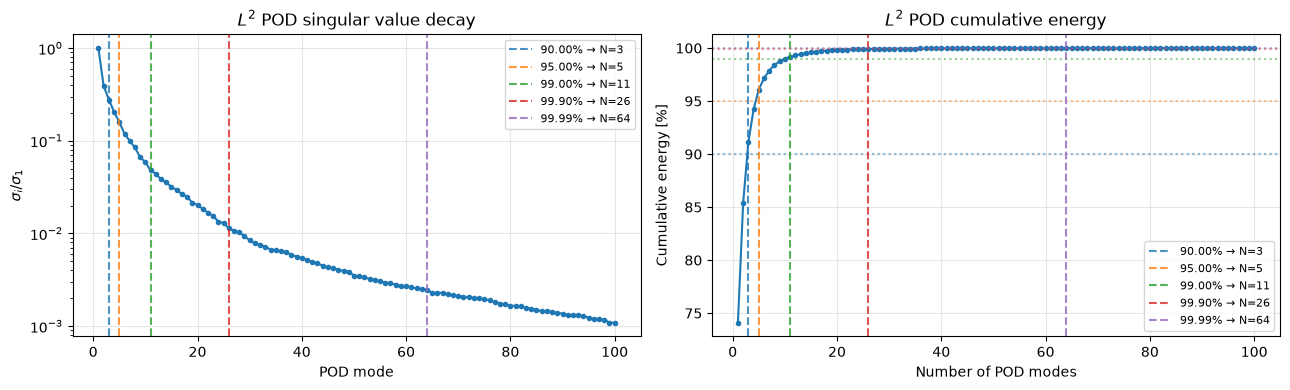

In [7]:

sf.plot_pod_analysis(
    s,
    total_energy=pod.total_energy
)

plt.show()


### 2.3 Reduced Dimension Selection

Although the singular value decay provides a first indication of the intrinsic dimensionality of the solution manifold, the final POD dimension should also account for approximation accuracy on unseen trajectories.

For a truncated basis $V_N$, the $L^2$-orthogonal projection of a FOM snapshot is

$$
\mathbf{u}_{\mathrm{POD}}=V_N\mathbf{a},
\qquad
\mathbf{a}=V_N^TM\mathbf{u}_h.
$$

The relative spatial projection error is defined as

$$
e_{\mathrm{POD}}(\boldsymbol{\mu},t;N)=
\frac{\|\mathbf{u}_h-\mathbf{u}_{\mathrm{POD}}\|_M}
{\|\mathbf{u}_h\|_M},
\qquad
\|\mathbf{v}\|_M=\sqrt{\mathbf{v}^TM\mathbf{v}}.
$$

To assess the effect of the reduced dimension, we evaluate three complementary metrics over the validation trajectories:

- **Mean relative error:** average over time for each trajectory, followed by averaging across trajectories.
- **Worst trajectory error:** maximum time-averaged relative error among validation trajectories.
- **Maximum snapshot error:** largest instantaneous relative error across the entire validation set.

The POD projection provides the best approximation within the selected linear subspace in the $L^2$ norm. Its error therefore represents the **minimum reconstruction error achievable by a POD-NN surrogate using the same basis**, independently of neural-network training.

We compare several reduced dimensions, including the energy-based candidate $N=26$, to identify a suitable compromise between projection accuracy and reduced-model complexity.


In [8]:
# POD dimension sensitivity on validation trajectories
n_modes_study = [3, 5, 10, 20, 26, 30, 35, 40, 45, 50, 60, 75, 100]

pod_errors = {}

for n in n_modes_study:
    if n > V.shape[1]:
        continue

    basis = V[:, :n]

    coefficients = sf.project_l2(u_val, basis, M)
    reconstruction = sf.reconstruct_pod(coefficients, basis)

    errors = sf.relative_l2_error(u_val, reconstruction, M)
    summary = sf.summarize_errors(errors)

    pod_errors[n] = {
        "mean": summary["mean_error"],
        "median": summary["median_error"],
        "worst_trajectory": summary["worst_trajectory_error"],
        "max_snapshot": summary["max_snapshot_error"]
    }

# Summary table
pod_df = pd.DataFrame.from_dict(pod_errors, orient="index")
pod_df.index.name = "POD modes"

display((100 * pod_df).round(3))


,mean,median,worst_trajectory,max_snapshot
POD modes,,,,
3,37.497,34.767,53.667,89.378
5,26.123,24.320,34.997,87.781
10,12.190,11.374,18.109,72.785
20,5.260,4.913,7.920,42.596
26,3.715,3.541,4.741,34.982
30,3.213,3.115,4.245,31.782
35,2.648,2.598,3.543,29.269
40,2.262,2.167,3.310,27.772
45,2.046,1.995,3.065,24.974


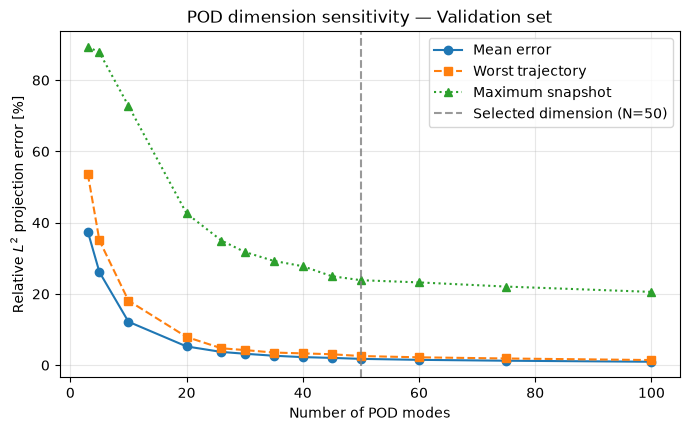

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for column, label, style in [
    ("mean", "Mean error", "o-"),
    ("worst_trajectory", "Worst trajectory", "s--"),
    ("max_snapshot", "Maximum snapshot", "^:")
]:
    ax.plot(
        pod_df.index,
        100 * pod_df[column],
        style,
        label=label
    )

ax.axvline(
    50,
    color="gray",
    linestyle="--",
    alpha=0.8,
    label="Selected dimension (N=50)"
)

ax.set(
    xlabel="Number of POD modes",
    ylabel=r"Relative $L^2$ projection error [%]",
    title="POD dimension sensitivity — Validation set"
)
ax.grid(alpha=0.3)
ax.legend()

plt.show()


#### Final POD dimension selection.

The cumulative energy analysis initially suggests $N=26$ modes, which capture approximately $99.9\%$ of the training snapshot energy.

However, the validation projection errors continue to decrease as additional modes are retained. This indicates that low-energy spatial structures remain relevant for accurately reconstructing some unseen states, particularly during the more challenging transient phases.

We therefore select **$N=50$ POD modes**, obtaining a mean relative validation projection error below $2\%$.

Although larger dimensions can further improve projection accuracy, they also increase the number of neural-network output coefficients and the reconstruction cost. The selected dimension offers a practical compromise between representational accuracy and surrogate complexity.

The final choice will be retained throughout the subsequent neural-network experiments.


In [10]:

# Final reduced dimension
n_modes = 50
assert n_modes <= V.shape[1]

# Truncated POD basis
Vn = V[:, :n_modes]

# M-orthonormality verification
G = Vn.T @ (M @ Vn)
orthogonality_error = G - np.eye(n_modes)

print(f"Selected POD dimension: N = {n_modes}")
print(f"M-orthonormality error (Frobenius): "
      f"{np.linalg.norm(orthogonality_error, 'fro'):.3e}")
print(f"Maximum entry-wise deviation: "
      f"{np.max(np.abs(orthogonality_error)):.3e}")

# POD coefficients
A_train = sf.project_l2(snapshots_train, Vn, M)
A_val = sf.project_l2(u_val, Vn, M)

# Validation projection
u_val_pod = sf.reconstruct_pod(A_val, Vn)

projection_errors = sf.relative_l2_error(u_val, u_val_pod, M)
projection_summary = sf.summarize_errors(projection_errors)

print(f"\nMean validation projection error: "
      f"{100 * projection_summary['mean_error']:.3f}%")
print(f"Worst trajectory error: "
      f"{100 * projection_summary['worst_trajectory_error']:.3f}%")
print(f"Maximum snapshot error: "
      f"{100 * projection_summary['max_snapshot_error']:.3f}%")


Selected POD dimension: N = 50
M-orthonormality error (Frobenius): 7.995e-12
Maximum entry-wise deviation: 3.557e-12

Mean validation projection error: 1.770%
Worst trajectory error: 2.562%
Maximum snapshot error: 23.849%


#### Final basis construction and orthonormality verification.

After selecting the reduced dimension, we extract the first $N=50$ POD modes and verify their numerical orthonormality.

The reduced Gram matrix is

$$
G=V_N^TMV_N.
$$

Ideally, $G=I_N$. We quantify numerical deviations through

$$
\varepsilon_{\mathrm{orth}}=\|G-I_N\|_F,
\qquad
\varepsilon_{\max}
=
\max_{i,j}|G_{ij}-\delta_{ij}|,
$$

where $\|\cdot\|_F$ denotes the Frobenius norm.

Small values confirm that the computed POD modes satisfy the expected $M$-orthonormality property to numerical precision.

The final basis is then used to compute the training and validation POD coefficients, without recomputing the decomposition.



**ROM Strategy: POD-NN vs DL-ROM**

The nonlinear Fisher-KPP equation presents challenges for a conventional POD-Galerkin ROM, since the nonlinear reaction term requires an efficient treatment of reduced operator evaluation, potentially involving hyper-reduction techniques.

We therefore adopt a non-intrusive, data-driven surrogate, which learns the parameter-time dependence directly from precomputed FOM solutions without evaluating the PDE residual online.

Among the available approaches, we select **POD-NN rather than a fully learned DL-ROM**, based on three considerations.

First, the mass-weighted POD analysis indicates that the solution manifold is already well approximated by a relatively small linear subspace. With $N=50$ modes, the mean relative validation projection error is below $2\%$, suggesting that nonlinear manifold learning is not essential to meet the prescribed accuracy requirement.

Second, the dataset contains only 60 independent training trajectories, corresponding to 2460 temporally correlated snapshots. A POD-NN requires learning only the parameter-time map to the reduced coefficients, whereas a DL-ROM would additionally require learning a nonlinear representation and reconstruction of the high-dimensional fields, introducing greater architectural complexity and training demands.

Finally, the $L^2$-orthonormal POD basis provides a physically consistent projection and an exact orthogonal decomposition between projection and regression errors, enabling transparent interpretation of the surrogate's limitations.

A DL-ROM could potentially achieve a more compact latent representation or improve the approximation of localized moving features. However, the present study does not include a trained DL-ROM benchmark, so no claim of comparative superiority is made.

The POD-NN is therefore selected as a simpler, interpretable and sufficiently accurate approach for the available dataset and the objectives of this assignment.



### 2.4 Temporal and Spatial Projection Error Analysis

After selecting the reduced dimension, we investigate how the POD projection accuracy evolves throughout the simulation.

For each time instant $t_j$, the mean relative projection error across validation trajectories is

$$
\overline{e}_{\mathrm{POD}}(t_j)
=
\frac{1}{N_{\mathrm{val}}}
\sum_{i=1}^{N_{\mathrm{val}}}
e_{i,j}^{\mathrm{POD}}(N).
$$

Its temporal average recovers the global validation metric:

$$
\overline{e}_{\mathrm{POD}}
=
\frac{1}{N_t}
\sum_{j=1}^{N_t}
\overline{e}_{\mathrm{POD}}(t_j).
$$

We visualize the individual trajectory errors, their time-dependent mean and the global average.

This allows us to identify temporal regions where the reduced space is less effective, distinguishing localized approximation difficulties from the overall accuracy measured by a single aggregate metric.


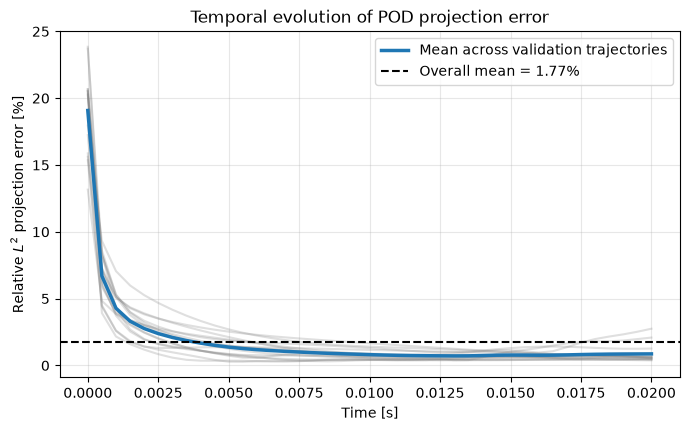

In [11]:

# Temporal evolution of the POD projection error
mean_error_time = projection_errors.mean(axis=0)
mean_error_global = projection_summary["mean_error"]

fig, ax = plt.subplots(figsize=(8, 4.5))

for errors in projection_errors:
    ax.plot(t, 100 * errors, color="gray", alpha=0.25)

ax.plot(
    t,
    100 * mean_error_time,
    linewidth=2.5,
    label="Mean across validation trajectories"
)

ax.axhline(
    100 * mean_error_global,
    color="black",
    linestyle="--",
    label=f"Overall mean = {100*mean_error_global:.2f}%"
)

ax.set(
    xlabel="Time [s]",
    ylabel=r"Relative $L^2$ projection error [%]",
    title="Temporal evolution of POD projection error"
)
ax.grid(alpha=0.3)
ax.legend()

plt.show()



#### Initial Transient and Error Normalization

The temporal error curves exhibit a pronounced initial transient, with substantially higher relative projection errors than during most of the subsequent evolution.

A high relative error can result either from an actual increase in the absolute approximation error or from a small norm of the reference solution.

To distinguish these effects, we compare the absolute projection error and the FOM solution norm:

$$
E_{\mathrm{abs}}(t)=
\|u_h(t)-u_{\mathrm{POD}}(t)\|_{L^2(\Omega)},
\qquad
U(t)=\|u_h(t)\|_{L^2(\Omega)}.
$$

Both quantities are averaged across validation trajectories to investigate the origin of the initial relative-error peak.


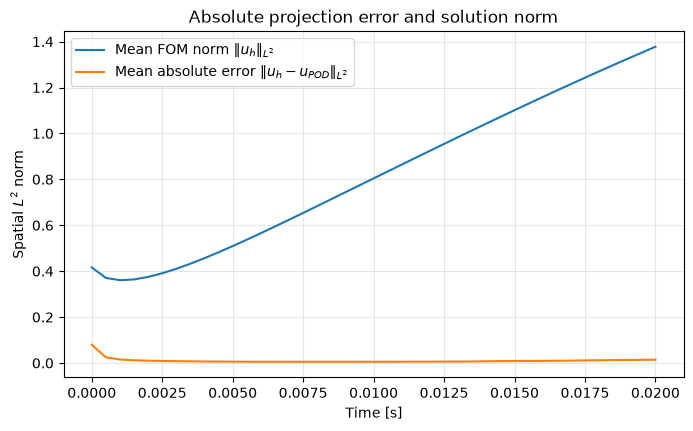

In [12]:

# Absolute spatial L2 errors and solution norms
solution_norm = sf.l2_norm(u_val, M)
absolute_error = sf.l2_norm(u_val - u_val_pod, M)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    t,
    solution_norm.mean(axis=0),
    label=r"Mean FOM norm $\|u_h\|_{L^2}$"
)

ax.plot(
    t,
    absolute_error.mean(axis=0),
    label=r"Mean absolute error $\|u_h-u_{POD}\|_{L^2}$"
)

ax.set(
    xlabel="Time [s]",
    ylabel=r"Spatial $L^2$ norm",
    title="Absolute projection error and solution norm"
)
ax.grid(alpha=0.3)
ax.legend()

plt.show()



**Interpretation.**

The initial relative-error peak is primarily associated with a genuinely larger absolute projection error, rather than a vanishing norm of the reference solution.

This behavior can be explained by the localized initial damage distribution. Its sharp spatial transitions and parameter-dependent position require the POD basis to represent different localized structures, making the early-time solution manifold relatively challenging to approximate with a limited number of global modes.

As diffusion smooths the damage distribution and the reaction term promotes the development of the propagation front, the projection error rapidly decreases.

A smaller increase in absolute error is observed near the end of the simulation. This suggests that some late-stage spatial configurations are less accurately represented by the retained modes, although the deterioration is considerably weaker than during the initial transient.

Overall, the $N=50$ POD basis provides an accurate representation throughout most of the simulation, with the largest approximation difficulties concentrated around localized and rapidly evolving spatial structures.



**Spatial distribution of projection errors.**

To complement the temporal analysis, we examine a representative validation trajectory at three stages: the initial condition, the early transient and the final time.

The representative trajectory is selected as the one whose time-averaged projection error is closest to the validation mean.

For each selected instant, we visualize the FOM damage field and the corresponding pointwise absolute POD projection error. Common color scales are used across time to enable direct comparisons.


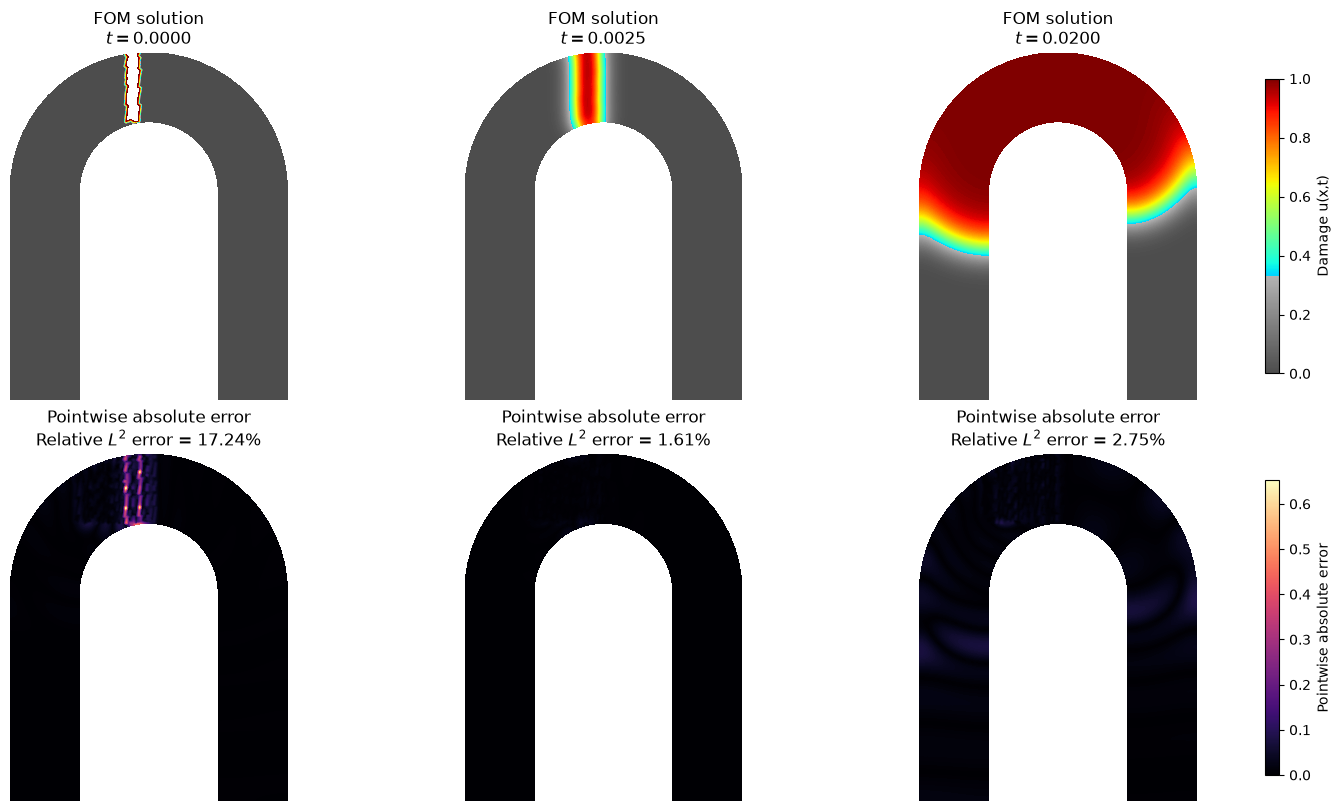

Representative validation trajectory: 11
Parameters: [0.28605382 0.95810557 0.77031293]
Mean projection error: 1.780%


In [13]:

# Representative validation trajectory
idx = projection_summary["representative_index"]

# Times of interest
times_to_plot = [0.0, 0.0025, T]
time_indices = [
    np.argmin(np.abs(t - target))
    for target in times_to_plot
]

# FOM and POD projection
u_traj = u_val[idx]
u_pod_traj = u_val_pod[idx]
abs_error = np.abs(u_traj - u_pod_traj)

# Common scales within each row
u_min, u_max = u_traj.min(), u_traj.max()
error_max = abs_error[time_indices].max()

cmap = sf.modify_jet_to_gray()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")

for k, j in enumerate(time_indices):

    # FOM solution
    plt.sca(axes[0, k])
    fe.plot(
        u_traj[j],
        Vh,
        vmin=u_min,
        vmax=u_max,
        cmap=cmap
    )
    plt.title(
        f"FOM solution\n"
        f"$t={t[j]:.4f}$"
    )

    # Pointwise absolute projection error
    plt.sca(axes[1, k])
    fe.plot(
        abs_error[j],
        Vh,
        vmin=0,
        vmax=error_max,
        cmap="magma"
    )
    plt.title(
        f"Pointwise absolute error\n"
        f"Relative $L^2$ error = {100*projection_errors[idx, j]:.2f}%"
    )

# Shared colorbars match the fixed scales used by the FEM plots.
fig.colorbar(
    ScalarMappable(norm=Normalize(u_min, u_max), cmap=cmap),
    ax=axes[0, :].tolist(), label="Damage u(x,t)", shrink=0.85
)
fig.colorbar(
    ScalarMappable(norm=Normalize(0, error_max), cmap="magma"),
    ax=axes[1, :].tolist(), label="Pointwise absolute error", shrink=0.85
)
plt.show()

print(f"Representative validation trajectory: {idx}")
print(f"Parameters: {mu_val[idx]}")
print(
    f"Mean projection error: "
    f"{100*projection_summary['trajectory_errors'][idx]:.3f}%"
)



**Physical interpretation.**

The spatial visualizations confirm the connection between POD accuracy and the evolution of the reaction-diffusion process.

Initially, the localized damage region introduces sharp spatial variations whose position depends on $\delta$. These parameter-dependent features are particularly difficult to represent using a truncated global linear basis, explaining the higher projection errors observed during the initial transient.

At intermediate times, diffusion smooths the field and the dominant POD modes provide a more accurate representation.

Near the final time, residual errors become more visible around the evolving damage front. However, their magnitude remains limited compared with the early transient.

These observations highlight a fundamental limitation of linear dimensionality reduction for parametrized problems involving localized or moving features, while confirming that the selected reduced space is sufficiently accurate for the subsequent POD-NN approximation.



## 3. POD-NN Surrogate Model


### 3.1 POD-NN Formulation

Having constructed and validated the POD basis, we develop a **non-intrusive reduced-order model** to approximate the parameter-to-solution map without solving the underlying nonlinear PDE during online evaluation.

The full-order solution is approximated in the previously selected POD space ($N=50$):

$$
\mathbf{u}_h(\boldsymbol{\mu},t)
\approx V_N\mathbf{a}(\boldsymbol{\mu},t),
\qquad
\mathbf{a}\in\mathbb{R}^N.
$$

Rather than predicting the $N_h=6636$ FOM degrees of freedom directly, a feedforward neural network learns the mapping from physical parameters and normalized time to the reduced coefficients:

$$
\mathcal{N}_{\boldsymbol{\theta}}:
[0,1]^4\longrightarrow\mathbb{R}^N,
\qquad
(\boldsymbol{\mu},t/T)\longmapsto
\hat{\mathbf{a}}(\boldsymbol{\mu},t).
$$

The reconstructed POD-NN solution is therefore

$$
\boxed{
\tilde{\mathbf{u}}_h(\boldsymbol{\mu},t)
=
V_N\hat{\mathbf{a}}(\boldsymbol{\mu},t).
}
$$

This approach separates spatial compression, performed by POD, from the nonlinear parameter-time regression performed by the neural network. Unlike POD-Galerkin, the online surrogate does not require assembling or solving a reduced dynamical system.

**Error decomposition.**

Since $V_N$ is $M$-orthonormal, the total squared spatial $L^2$ reconstruction error can be decomposed into two orthogonal contributions:

$$
\boxed{
\|\mathbf{u}_h-\tilde{\mathbf{u}}_h\|_M^2
=
\underbrace{\|\mathbf{u}_h-V_N\mathbf{a}\|_M^2}_{\text{POD projection error}}
+
\underbrace{\|\mathbf{a}-\hat{\mathbf{a}}\|_2^2}_{\text{NN regression error}}.
}
$$

The first term measures the representational limitation of the chosen POD space, while the second measures the neural network's ability to predict the reduced coefficients.

Thus, for a fixed POD basis, the network can only reduce the regression component. This distinction will be used later to interpret the surrogate's total approximation error.



### 3.2 Data Preparation and Coefficient Scaling

Each FOM trajectory is associated with a fixed parameter vector $\boldsymbol{\mu}_i$ and contains $N_t=41$ temporal snapshots.

To construct the supervised learning dataset, every parameter configuration is paired with each time instant, generating one input sample per snapshot:

$$
\mathbf{x}_{i,j}
=
\begin{bmatrix}
\mu_{i,1} & \mu_{i,2} & \mu_{i,3} & t_j/T
\end{bmatrix}^{T}
\in[0,1]^4.
$$

The corresponding target is the reduced coefficient vector obtained through the $L^2$-orthogonal POD projection:

$$
\mathbf{a}_{i,j}=V_N^TM\mathbf{u}_{h,i,j}.
$$

The training and validation coefficients were already computed in Section 2.3, using the same POD basis constructed exclusively from training data.

**Coefficient scaling.**

Although the physical parameters are already normalized and time is rescaled to $[0,1]$, the POD coefficients may have substantially different magnitudes.

We therefore apply independent min-max scaling to each coefficient:

$$
a_k^{\mathrm{scaled}}
=
\frac{a_k-a_k^{\min}}{a_k^{\max}-a_k^{\min}},
\qquad k=1,\ldots,N.
$$

The scaling statistics are computed exclusively from the training coefficients and subsequently reused for validation and test data. No clipping is applied to values outside the training range.

The network predicts scaled coefficients, which are transformed back to their original magnitude before computing the training loss and reconstructing the physical solution.


In [14]:
# Supervised NN inputs: [mu1, mu2, mu3, t/T]
X_train_nn = sf.make_nn_inputs(mu_train, t)
X_val_nn = sf.make_nn_inputs(mu_val, t)

# Coefficient scaling fitted exclusively on training data
scaler = sf.fit_coefficient_scaler(A_train)

# Verify consistency with the POD coefficients
assert X_train_nn.shape == (len(mu_train) * N_t, 4)
assert X_val_nn.shape == (len(mu_val) * N_t, 4)

assert A_train.shape == (len(X_train_nn), n_modes)
assert A_val.shape == (len(mu_val), N_t, n_modes)

print(f"Training inputs     : {X_train_nn.shape}")
print(f"Training targets    : {A_train.shape}")
print(f"Validation inputs   : {X_val_nn.shape}")
print(f"Validation targets  : {A_val.shape}")
print(f"NN mapping          : 4 -> {n_modes}")


# Flatten validation targets to match the NN sample ordering
A_val = A_val.reshape(-1, n_modes)

assert A_val.shape == (len(X_val_nn), n_modes)


Training inputs     : (2460, 4)
Training targets    : (2460, 50)
Validation inputs   : (615, 4)
Validation targets  : (15, 41, 50)
NN mapping          : 4 -> 50



### 3.3 Neural Network Architecture and Training Strategy

We employ a fully connected **multilayer perceptron (MLP)** to approximate the nonlinear mapping from the three physical parameters and normalized time to the $N=50$ reduced coefficients.

For each hidden layer, the transformation is

$$
\mathbf{h}^{(\ell+1)}
=
\sigma\left(
W^{(\ell)}\mathbf{h}^{(\ell)}+\mathbf{b}^{(\ell)}
\right),
$$

where $W^{(\ell)}$ and $\mathbf{b}^{(\ell)}$ are trainable weights and biases, while $\sigma$ denotes the activation function.

The output layer is linear, allowing the network to predict arbitrary scaled coefficient values without imposing artificial bounds.

**Training objective.**

The loss is computed using the **unscaled POD coefficients**, ensuring consistency with the spatial $L^2$ norm.

Since $V_N^TMV_N=I_N$,

$$
\|V_N\mathbf{a}-V_N\hat{\mathbf{a}}\|_M^2
=
\|\mathbf{a}-\hat{\mathbf{a}}\|_2^2.
$$

The implemented loss is the mean squared coefficient error:

$$
\boxed{
\mathcal{L}(\boldsymbol{\theta})
=
\frac{1}{N_sN}
\sum_{s=1}^{N_s}
\left\|
\mathbf{a}_s-
\hat{\mathbf{a}}_s(\boldsymbol{\theta})
\right\|_2^2.
}
$$

The factor $1/N$ does not change the minimizer for a fixed reduced dimension. However, the loss is not identical to the mean relative $L^2$ error required by the assignment, which is used separately to evaluate surrogate accuracy.

**Optimization and model selection.**

The neural network is trained using mini-batch Adam optimization. A `ReduceLROnPlateau` scheduler reduces the learning rate when the validation coefficient loss stops improving.

The model checkpoint corresponding to the minimum validation coefficient loss is retained. Training runs for the prescribed maximum number of epochs, without early stopping.

To assess the predictive performance of each trained model, we reconstruct the full-order fields and compute the mean relative spatial $L^2$ error on the validation trajectories.

**Experimental strategy.**

We begin with a relatively small baseline MLP and subsequently investigate the influence of network width, depth, learning rate, weight decay and activation function.

All configurations use the same training-validation split and fixed POD basis, allowing consistent comparisons. The extensive hyperparameter study and final model selection are presented in Chapter 4.



## 4. Hyperparameter Optimization and Model Selection

The POD-NN hyperparameters are investigated through a validation-based experimental study. All models share the same training-validation split, POD basis ($N=50$), coefficient scaling and evaluation metric.

The primary selection criterion is the mean relative spatial $L^2$ validation error, while worst-trajectory accuracy and model complexity are considered as complementary indicators. The test set is reserved for the final evaluation.

In [15]:

# Shared hyperparameter tuning utilities
excel_path = Path("tuning_results.xlsx")
model_dir = "models"

def save_experiment_table(df, sheet_name):
    """Merge experiment rows into one sheet of the tuning workbook and return them.
    
    Deduplicate by Experiment ID, keep the latest row, and sort by mean validation
    L2 error. Preserve other sheets and add a frozen header and filter."""
    if excel_path.exists():
        with pd.ExcelFile(excel_path) as xls:
            if sheet_name in xls.sheet_names:
                old = pd.read_excel(xls, sheet_name=sheet_name)
                df = pd.concat([old, df], ignore_index=True)

    df = (
        df.drop_duplicates(subset="Experiment ID", keep="last")
          .sort_values("Mean L2 [%]")
          .reset_index(drop=True)
    )

    kwargs = (
        {"mode": "a", "if_sheet_exists": "replace"}
        if excel_path.exists() else {"mode": "w"}
    )

    with pd.ExcelWriter(excel_path, engine="openpyxl", **kwargs) as writer:
        df.to_excel(writer, sheet_name=sheet_name, index=False)
        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

    return df


def run_tuning(configurations, sheet_name):
    """Train or reload named POD-NN configurations and persist validation metrics.
    
    Use the enclosing training/validation arrays and cache settings. Return
    (results, table), where table is the selected workbook sheet sorted by
    mean validation L2 error. Test data are not used."""
    results = {}

    for name, config in configurations.items():
        print(f"\n{'='*55}\n{name}\n{'='*55}")

        result = sf.run_cached_experiment(
            config,
            X_train_nn, A_train,
            X_val_nn, A_val,
            scaler, u_val, Vn, M,
            model_dir=model_dir,
            device=device
        )

        results[name] = result

        row = {
            "Experiment ID": result["experiment_id"],
            "Name": name,
            "Width": config["hidden_layers"][0],
            "Depth": len(config["hidden_layers"]),
            "Activation": config["activation"],
            "Learning rate": config["lr"],
            "Weight decay": config["weight_decay"],
            "Seed": config["seed"],
            "Parameters": result["parameters"],
            "Best epoch": result["best_epoch"],
            "Coefficient MSE": result["best_val_loss"],
            "Mean L2 [%]": 100 * result["metrics"]["mean_error"],
            "Worst trajectory [%]":
                100 * result["metrics"]["worst_trajectory_error"],
            "Max snapshot [%]":
                100 * result["metrics"]["max_snapshot_error"],
            "Checkpoint": result["checkpoint_path"],
        }

        save_experiment_table(pd.DataFrame([row]), sheet_name)

    df = pd.read_excel(excel_path, sheet_name=sheet_name)
    df = df.sort_values("Mean L2 [%]").reset_index(drop=True)

    return results, df


### 4.1 Architecture Search

We first investigate the effect of MLP width and depth, starting from a baseline architecture with three hidden layers of 64 neurons.

Six configurations are compared, using LeakyReLU activation, learning rate $\eta=10^{-3}$, zero weight decay and 1500 training epochs.

For an MLP with input dimension $d_{\mathrm{in}}=4$, output dimension $d_{\mathrm{out}}=50$ and hidden widths $h_1,\ldots,h_L$, the number of trainable parameters is

$$
P=(d_{\mathrm{in}}+1)h_1+
\sum_{\ell=1}^{L-1}(h_\ell+1)h_{\ell+1}
+(h_L+1)d_{\mathrm{out}}.
$$

This allows us to compare improvements in predictive accuracy against the increase in network complexity.

The baseline and wider/deeper architectures are evaluated under identical training settings. Smaller preliminary architectures with 16–32 neurons were discarded after showing inferior validation performance.


In [16]:

architectures = [
    (64, 3),
    (64, 4),
    (128, 3),
    (256, 3),
    (128, 4),
    (128, 5),
]

architecture_configs = {
    f"W{width}_D{depth}": {
        "hidden_layers": (width,) * depth,
        "activation": "leaky_relu",
        "lr": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 64,
        "max_epochs": 1500,
        "seed": 42,
    }
    for width, depth in architectures
}

architecture_results, architecture_df = run_tuning(
    architecture_configs,
    sheet_name="architecture"
)

display(
    architecture_df
    .dropna(subset=["Name"])
    [["Name", "Parameters", "Mean L2 [%]",
      "Worst trajectory [%]", "Best epoch"]]
    .round(3)
)



W64_D3
Training already exists — loading checkpoint
Parameters: 11,890 | Best epoch: 983
Validation coefficient MSE: 8.574821e-05
Mean relative L2: 8.051% | Worst trajectory: 12.907% | Max snapshot: 55.240%

W64_D4
Training already exists — loading checkpoint
Parameters: 16,050 | Best epoch: 1490
Validation coefficient MSE: 5.446976e-05
Mean relative L2: 6.286% | Worst trajectory: 10.642% | Max snapshot: 43.397%

W128_D3
Training already exists — loading checkpoint
Parameters: 40,114 | Best epoch: 750
Validation coefficient MSE: 6.654263e-05
Mean relative L2: 7.158% | Worst trajectory: 12.150% | Max snapshot: 64.219%

W256_D3
Training already exists — loading checkpoint
Parameters: 145,714 | Best epoch: 301
Validation coefficient MSE: 7.462726e-05
Mean relative L2: 6.866% | Worst trajectory: 14.433% | Max snapshot: 58.588%

W128_D4
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 685
Validation coefficient MSE: 4.131647e-05
Mean relative L2: 5.844% | Worst

,Name,Parameters,Mean L2 [%],Worst trajectory [%],Best epoch
0,W128_D5,73138,5.004,8.718,584
3,W128_D4,56626,5.844,11.265,685
5,W64_D4,16050,6.286,10.642,1490
8,W256_D3,145714,6.866,14.433,301
9,W128_D3,40114,7.158,12.150,750
11,W64_D3,11890,8.051,12.907,983



**Architecture selection.**

The architecture search shows that increasing network capacity improves the representation of the nonlinear parameter-time dependence, although the benefit is not uniform across configurations.

The two most promising architectures are **128 × 4** and **128 × 5**, achieving mean relative validation errors of approximately **5.8% and 5%**, respectively, with LeakyReLU.

The deeper network provides a modest accuracy improvement at the cost of additional trainable parameters. Both architectures are therefore retained for the following experiments, allowing us to assess whether changes in activation and optimization settings affect their relative performance.



### 4.2 Activation Function Selection

We investigate the influence of the activation function on the accuracy of the two selected architectures, keeping the learning rate fixed at $10^{-3}$ and weight decay at zero.

Four activation functions are compared:

- **LeakyReLU:** maintains a nonzero gradient for negative inputs.
- **ReLU:** a simple piecewise-linear activation.
- **Tanh:** a smooth, bounded nonlinear activation.
- **SiLU (Swish):** a smooth, non-monotonic activation defined by

$$
\operatorname{SiLU}(x)=x\,\sigma(x)=\frac{x}{1+e^{-x}}.
$$

Since the neural network approximates a continuous parameter-time mapping, smooth activation functions may offer advantages when representing the evolving POD coefficients. Nevertheless, their effectiveness is assessed empirically through validation errors.

All eight configurations are evaluated using the same POD basis and training procedure.


In [17]:

activations = ["leaky_relu", "relu", "tanh", "silu"]

activation_configs = {
    f"W{width}_D{depth}_{activation}": {
        "hidden_layers": (width,) * depth,
        "activation": activation,
        "lr": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 64,
        "max_epochs": 1500,
        "seed": 42,
    }
    for width, depth in [(128, 4), (128, 5)]
    for activation in activations
}

activation_results, activation_df = run_tuning(
    activation_configs,
    sheet_name="activation_function"
)

display(activation_df.dropna(subset=["Name"])[
    ["Name", "Mean L2 [%]", "Worst trajectory [%]"]
].round(4))


W128_D4_leaky_relu
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 685
Validation coefficient MSE: 4.131647e-05
Mean relative L2: 5.844% | Worst trajectory: 11.265% | Max snapshot: 52.308%

W128_D4_relu
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 957
Validation coefficient MSE: 6.915100e-05
Mean relative L2: 6.758% | Worst trajectory: 11.961% | Max snapshot: 48.821%

W128_D4_tanh
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1429
Validation coefficient MSE: 2.636392e-05
Mean relative L2: 3.777% | Worst trajectory: 9.801% | Max snapshot: 46.467%

W128_D4_silu
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1194
Validation coefficient MSE: 1.499739e-05
Mean relative L2: 3.286% | Worst trajectory: 5.969% | Max snapshot: 40.274%

W128_D5_leaky_relu
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 584
Validation coefficient MSE: 4.489468

,Name,Mean L2 [%],Worst trajectory [%]
0,W128_D5_silu,3.0774,4.4485
3,W128_D4_silu,3.2857,5.9690
5,W128_D5_tanh,3.3696,6.1865
7,W128_D4_tanh,3.7773,9.8008
8,W128_D5_leaky_relu,5.0038,8.7180
11,W128_D4_leaky_relu,5.8435,11.2647
13,W128_D5_relu,6.2579,10.2020
14,W128_D4_relu,6.7580,11.9608



### 4.3 SiLU Hyperparameter Refinement

After identifying SiLU as the most promising activation function, we refine the optimization settings for the 128 × 4 and 128 × 5 architectures.

Two complementary studies are performed:

**Learning rate.** We compare $\eta\in\{3\times10^{-4},10^{-3},3\times10^{-3}\}$ with zero weight decay.

**Weight decay.** We compare $\lambda\in\{0,10^{-6},10^{-5},10^{-4}\}$ at a fixed learning rate $\eta=3\times10^{-3}$.

Weight decay introduces a parameter penalty through the optimization procedure, discouraging large network weights and potentially improving generalization. The parameter $\lambda$ controls the regularization strength.

For both studies, the remaining hyperparameters are unchanged. The comparisons are conducted separately rather than as a complete joint search over all possible learning-rate and regularization combinations.


In [18]:

learning_rates = [3e-4, 1e-3, 3e-3]

lr_configs = {
    f"W{width}_D{depth}_LR{lr:.1e}": {
        "hidden_layers": (width,) * depth,
        "activation": "silu",
        "lr": lr,
        "weight_decay": 0.0,
        "batch_size": 64,
        "max_epochs": 1500,
        "seed": 42,
    }
    for width, depth in [(128, 4), (128, 5)]
    for lr in learning_rates
}

learning_rate_results, learning_rate_df = run_tuning(
    lr_configs,
    sheet_name="learning_rate"
)

display(learning_rate_df.dropna(subset=["Name"])[
    ["Name", "Learning rate", "Mean L2 [%]",
     "Worst trajectory [%]", "Best epoch"]
].round(4))



W128_D4_LR3.0e-04
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1489
Validation coefficient MSE: 2.265984e-05
Mean relative L2: 3.735% | Worst trajectory: 5.603% | Max snapshot: 37.981%

W128_D4_LR1.0e-03
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1194
Validation coefficient MSE: 1.499739e-05
Mean relative L2: 3.286% | Worst trajectory: 5.969% | Max snapshot: 40.274%

W128_D4_LR3.0e-03
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 960
Validation coefficient MSE: 1.436020e-05
Mean relative L2: 3.275% | Worst trajectory: 5.170% | Max snapshot: 40.149%

W128_D5_LR3.0e-04
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1478
Validation coefficient MSE: 1.335765e-05
Mean relative L2: 3.285% | Worst trajectory: 4.848% | Max snapshot: 35.190%

W128_D5_LR1.0e-03
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 894
Validation coefficient M

,Name,Learning rate,Mean L2 [%],Worst trajectory [%],Best epoch
0,W128_D5_LR3.0e-03,0.0030,2.8453,4.6246,1144
2,W128_D5_LR1.0e-03,0.0010,3.0774,4.4485,894
6,W128_D4_LR3.0e-03,0.0030,3.2747,5.1699,960
7,W128_D5_LR3.0e-04,0.0003,3.2851,4.8478,1478
8,W128_D4_LR1.0e-03,0.0010,3.2857,5.9690,1194
11,W128_D4_LR3.0e-04,0.0003,3.7355,5.6033,1489


In [19]:

weight_decays = [0.0, 1e-6, 1e-5, 1e-4]

wd_configs = {
    f"W{width}_D{depth}_WD{wd:.0e}": {
        "hidden_layers": (width,) * depth,
        "activation": "silu",
        "lr": 3e-3,
        "weight_decay": wd,
        "batch_size": 64,
        "max_epochs": 1500,
        "seed": 42,
    }
    for width, depth in [(128, 4), (128, 5)]
    for wd in weight_decays
}

weight_decay_results, weight_decay_df = run_tuning(
    wd_configs,
    sheet_name="weight_decay"
)

display(weight_decay_df.dropna(subset=["Name"])[
    ["Name", "Weight decay", "Mean L2 [%]",
     "Worst trajectory [%]", "Best epoch"]
].round(6))



W128_D4_WD0e+00
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 960
Validation coefficient MSE: 1.436020e-05
Mean relative L2: 3.275% | Worst trajectory: 5.170% | Max snapshot: 40.149%

W128_D4_WD1e-06
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1467
Validation coefficient MSE: 5.108245e-05
Mean relative L2: 6.188% | Worst trajectory: 9.178% | Max snapshot: 51.721%

W128_D4_WD1e-05
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 887
Validation coefficient MSE: 2.268230e-04
Mean relative L2: 13.987% | Worst trajectory: 18.215% | Max snapshot: 76.353%

W128_D4_WD1e-04
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1456
Validation coefficient MSE: 1.216870e-03
Mean relative L2: 34.569% | Worst trajectory: 48.769% | Max snapshot: 104.423%

W128_D5_WD0e+00
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1144
Validation coefficient MSE: 9

,Name,Weight decay,Mean L2 [%],Worst trajectory [%],Best epoch
0,W128_D5_WD0e+00,0.000000,2.845334,4.624552,1144
4,W128_D4_WD0e+00,0.000000,3.274693,5.169919,960
5,W128_D5_WD1e-06,0.000001,5.262158,6.775356,1495
9,W128_D4_WD1e-06,0.000001,6.187593,9.178118,1467
13,W128_D5_WD1e-05,0.000010,12.160584,15.686271,1496
15,W128_D4_WD1e-05,0.000010,13.986877,18.214557,887
16,W128_D4_WD1e-04,0.000100,34.568731,48.768572,1456
18,W128_D5_WD1e-04,0.000100,35.124707,53.024641,977



**Optimization hyperparameter assessment.**

The SiLU-based experiments indicate that the learning rate has a substantial influence on convergence and validation accuracy.

Among the investigated values, $\eta=3\times10^{-3}$ provides the most favorable performance for the selected architecture.

Conversely, increasing weight decay does not improve the mean relative validation error under the tested conditions. Stronger regularization tends to deteriorate predictive accuracy, suggesting that weight penalization is not beneficial for these configurations.

We therefore retain **zero weight decay** and an initial learning rate of $3\times10^{-3}$.

Combining these results with the architecture and activation studies leads to a selected configuration with five hidden layers of 128 neurons and SiLU activation.



### 4.4 Random-Seed Robustness

The selected POD-NN configuration is trained with five different random seeds to assess the sensitivity of its performance to weight initialization and mini-batch ordering.

All hyperparameters, the POD basis and the dataset partition remain fixed. Only the random seed is varied.

For each run, the mean relative validation error is recorded. We summarize the resulting variability through

$$
\bar e=\frac{1}{K}\sum_{k=1}^{K}e_k,
\qquad
s_e=\sqrt{\frac{1}{K-1}\sum_{k=1}^{K}(e_k-\bar e)^2},
$$

where $K=5$ is the number of independent training runs.

We additionally examine worst-trajectory and maximum-snapshot errors to assess whether changes in initialization affect the most challenging predictions.

Training times are recorded only for newly executed training runs. Previously measured times are preserved when checkpoints are retrieved from cache.


In [20]:

seeds = [42, 0, 1, 2, 3]

selected_config = {
    "hidden_layers": (128,) * 5,
    "activation": "silu",
    "lr": 3e-3,
    "weight_decay": 0.0,
    "batch_size": 64,
    "max_epochs": 1500,
}

seed_results = {}
seed_rows = []

sheet_name = "seed_robustness"

for seed in seeds:
    config = {**selected_config, "seed": seed}

    print(f"\n{'='*55}\nSeed: {seed}\n{'='*55}")

    start = perf_counter()

    result = sf.run_cached_experiment(
        config,
        X_train_nn, A_train,
        X_val_nn, A_val,
        scaler, u_val, Vn, M,
        model_dir=model_dir,
        device=device
    )

    elapsed = perf_counter() - start

    # Recover previously measured training time
    previous_time = np.nan

    if excel_path.exists():
        with pd.ExcelFile(excel_path) as xls:
            if sheet_name in xls.sheet_names:
                old_df = pd.read_excel(xls, sheet_name=sheet_name)

                if {"Experiment ID", "Training time [s]"}.issubset(old_df.columns):
                    previous = old_df.loc[
                        old_df["Experiment ID"] == result["experiment_id"],
                        "Training time [s]"
                    ].dropna()

                    if not previous.empty:
                        previous_time = previous.iloc[0]

    if pd.notna(previous_time):
        training_time = float(previous_time)
        print("Training time exists — preserved")
    elif not result["cached"]:
        training_time = elapsed
        print("New training time recorded")
    else:
        training_time = np.nan
        print("Cached — training time unavailable")

    seed_results[seed] = result

    row = {
        "Experiment ID": result["experiment_id"],
        "Seed": seed,
        "Width": 128,
        "Depth": 5,
        "Activation": "silu",
        "Learning rate": config["lr"],
        "Weight decay": config["weight_decay"],
        "Parameters": result["parameters"],
        "Best epoch": result["best_epoch"],
        "Coefficient MSE": result["best_val_loss"],
        "Mean L2 [%]": 100 * result["metrics"]["mean_error"],
        "Worst trajectory [%]":
            100 * result["metrics"]["worst_trajectory_error"],
        "Max snapshot [%]":
            100 * result["metrics"]["max_snapshot_error"],
        "Checkpoint": result["checkpoint_path"],
        "Training time [s]": training_time,
        "Training time [min]": training_time / 60,
        "Cached": result["cached"]
    }

    seed_rows.append(row)

    # Preserve previously measured times while updating results
    new_df = pd.DataFrame([row])

    if excel_path.exists():
        with pd.ExcelFile(excel_path) as xls:
            if sheet_name in xls.sheet_names:
                old_df = pd.read_excel(xls, sheet_name=sheet_name)
                new_df = pd.concat([old_df, new_df], ignore_index=True)

    new_df = (
        new_df.drop_duplicates(subset="Experiment ID", keep="first")
              .sort_values("Seed")
              .reset_index(drop=True)
    )

    kwargs = (
        {"mode": "a", "if_sheet_exists": "replace"}
        if excel_path.exists() else {"mode": "w"}
    )

    with pd.ExcelWriter(excel_path, engine="openpyxl", **kwargs) as writer:
        new_df.to_excel(writer, sheet_name=sheet_name, index=False)

        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

# Complete seed results
seed_df = (
    pd.read_excel(excel_path, sheet_name=sheet_name)
    .drop_duplicates(subset="Seed", keep="last")
    .sort_values("Seed")
    .reset_index(drop=True)
)
metric_cols = [
    "Mean L2 [%]",
    "Worst trajectory [%]",
    "Max snapshot [%]"
]

seed_summary = pd.DataFrame({
    "Mean": seed_df[metric_cols].mean(),
    "Std": seed_df[metric_cols].std(ddof=1),
    "Min": seed_df[metric_cols].min(),
    "Max": seed_df[metric_cols].max()
})

display(seed_df[
    ["Seed", "Mean L2 [%]", "Worst trajectory [%]",
     "Max snapshot [%]", "Training time [min]"]
].round(3))

display(seed_summary.round(3))



Seed: 42
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1144
Validation coefficient MSE: 9.119221e-06
Mean relative L2: 2.845% | Worst trajectory: 4.625% | Max snapshot: 36.673%
Cached — training time unavailable

Seed: 0
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 685
Validation coefficient MSE: 1.234591e-05
Mean relative L2: 3.347% | Worst trajectory: 4.638% | Max snapshot: 38.601%
Training time exists — preserved

Seed: 1
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 766
Validation coefficient MSE: 1.029360e-05
Mean relative L2: 3.246% | Worst trajectory: 4.654% | Max snapshot: 36.684%
Training time exists — preserved

Seed: 2
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 870
Validation coefficient MSE: 1.026929e-05
Mean relative L2: 2.944% | Worst trajectory: 4.128% | Max snapshot: 44.755%
Training time exists — preserved

Seed: 3
Training already exists

,Seed,Mean L2 [%],Worst trajectory [%],Max snapshot [%],Training time [min]
0,0,3.347,4.638,38.601,2.336
1,1,3.246,4.654,36.684,2.077
2,2,2.944,4.128,44.755,2.100
3,3,2.994,4.355,36.428,1.935
4,42,2.845,4.625,36.673,NaN


,Mean,Std,Min,Max
Mean L2 [%],3.075,0.212,2.845,3.347
Worst trajectory [%],4.480,0.232,4.128,4.654
Max snapshot [%],38.628,3.535,36.428,44.755


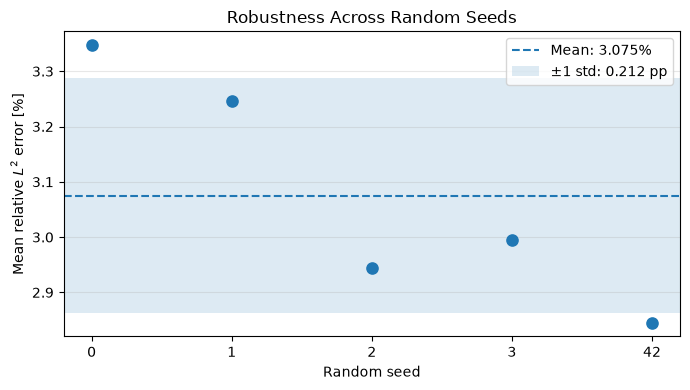

In [21]:

fig, ax = plt.subplots(figsize=(7, 4))

errors = seed_df["Mean L2 [%]"].to_numpy()
seed_ids = seed_df["Seed"].to_numpy()

mean_error = errors.mean()
std_error = errors.std(ddof=1)

x = np.arange(len(seed_ids))

ax.scatter(x, errors, s=65, zorder=3)

ax.axhline(
    mean_error,
    linestyle="--",
    label=f"Mean: {mean_error:.3f}%"
)

ax.axhspan(
    mean_error - std_error,
    mean_error + std_error,
    alpha=0.15,
    label=f"±1 std: {std_error:.3f} pp"
)

ax.set_xticks(x, seed_ids)
ax.set(
    xlabel="Random seed",
    ylabel=r"Mean relative $L^2$ error [%]",
    title="Robustness Across Random Seeds"
)
ax.grid(alpha=0.3, axis="y")
ax.legend()

plt.tight_layout()
plt.show()



### 4.5 Final Model Selection

Based on the validation experiments, the final POD-NN configuration is defined by:

| Hyperparameter | Selected value |
|---|---|
| POD dimension | 50 |
| Hidden layers | 5 |
| Neurons per hidden layer | 128 |
| Activation | SiLU |
| Learning rate | $3\times10^{-3}$ |
| Weight decay | 0 |
| Batch size | 64 |
| Maximum epochs | 1500 |
| Random seed | 42 |

The model is selected primarily for its low mean relative $L^2$ validation error, while also accounting for model complexity, worst-trajectory performance and robustness across random initializations.

The seed-42 checkpoint is retained as the reference model for the remaining analysis. This choice is not intended to select the most favorable random initialization, but to use a fixed, reproducible realization of the selected architecture.

From this point onward, the model configuration and checkpoint remain unchanged. The following chapters examine its error structure, generalization to the unseen test set and computational performance.


In [22]:

# Frozen final POD-NN configuration
final_config = {
    **selected_config,
    "seed": 42
}

# Load the existing checkpoint, or train if unavailable
final_result = sf.run_cached_experiment(
    final_config,
    X_train_nn, A_train,
    X_val_nn, A_val,
    scaler, u_val, Vn, M,
    model_dir=model_dir,
    device=device
)

final_model = final_result["model"]
final_model.eval()

assert Path(final_result["checkpoint_path"]).exists()

print("\nFinal POD-NN model")
print("-" * 45)
print(f"Checkpoint : {final_result['checkpoint_path']}")
print(f"Experiment : {final_result['experiment_id']}")
print(f"Parameters : {final_result['parameters']:,}")
print(f"Best epoch : {final_result['best_epoch']}")
print(
    f"Validation : "
    f"{100*final_result['metrics']['mean_error']:.3f}%"
)


Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1144
Validation coefficient MSE: 9.119221e-06
Mean relative L2: 2.845% | Worst trajectory: 4.625% | Max snapshot: 36.673%

Final POD-NN model
---------------------------------------------
Checkpoint : models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_bs64_ep1500_s42_54397a189d4a7f92.pt
Experiment : 54397a189d4a7f92
Parameters : 73,138
Best epoch : 1144
Validation : 2.845%



## 5. Model Evaluation and Generalization Analysis

### 5.1 Overall Accuracy and Generalization

After completing hyperparameter optimization, the final POD-NN model is evaluated on the training, validation and previously unseen test trajectories.

The POD basis ($N=50$), coefficient scaler, neural-network architecture and trained weights remain fixed. No further optimization or model selection is performed using test data.

The three datasets have distinct roles:

- **Training (60 trajectories):** assessment of in-sample reconstruction accuracy.
- **Validation (15 trajectories):** performance on the data previously used for hyperparameter and checkpoint selection.
- **Test (25 trajectories):** independent evaluation of generalization to unseen parameter configurations.

The primary accuracy measure is the mean relative spatial $L^2$ error, averaged over time and trajectories, as defined in Section 2.3. For the test set, the assignment considers the surrogate satisfactory if this error is below $10\%$.

We additionally report the median trajectory error, worst time-averaged trajectory error and maximum instantaneous snapshot error to characterize the distribution of prediction accuracy.

All errors are computed using the same FEM mass matrix and evaluation procedure.


In [23]:

# Frozen final model
final_model.eval()
final_model.requires_grad_(False)

# Dataset definitions
datasets = {
    "Training": (mu_train, u_train),
    "Validation": (mu_val, u_val),
    "Test": (mu_test, u_test),
}

evaluation = {}

for name, (mu_set, u_set) in datasets.items():

    # POD-NN prediction
    X = sf.make_nn_inputs(mu_set, t)

    result = sf.evaluate_model_L2(
        final_model, X, u_set, Vn, M, scaler
    )

    # Orthogonal POD projection using the frozen basis
    A_proj = sf.project_l2(u_set, Vn, M)
    u_pod = sf.reconstruct_pod(A_proj, Vn)

    # Error components
    e_total = result["errors"]
    e_pod = sf.relative_l2_error(u_set, u_pod, M)

    fom_norm = sf.l2_norm(u_set, M)

    e_reg = (
        sf.l2_norm(u_pod - result["prediction"], M)
        / fom_norm
    )

    evaluation[name] = {
        "mu": mu_set,
        "fom": u_set,
        "prediction": result["prediction"],
        "pod": u_pod,
        "norms": fom_norm,
        "total": e_total,
        "projection": e_pod,
        "regression": e_reg,
        "summary": result,
    }

    print(
        f"{name:10s} | "
        f"Mean L2 = {100 * result['mean_error']:.3f}%"
    )

# Assignment acceptance criterion
test_error = evaluation["Test"]["summary"]["mean_error"]

print(
    "\nAssignment accuracy criterion (< 10%):",
    "PASS" if test_error < 0.10 else "FAIL"
)


Training   | Mean L2 = 2.022%
Validation | Mean L2 = 2.845%
Test       | Mean L2 = 3.242%

Assignment accuracy criterion (< 10%): PASS


In [24]:

accuracy_rows = []

for name, data in evaluation.items():
    summary = data["summary"]

    accuracy_rows.append({
        "Dataset": name,
        "Trajectories": len(data["mu"]),
        "Mean L2 [%]": 100 * summary["mean_error"],
        "Median trajectory [%]": 100 * summary["median_error"],
        "Worst trajectory [%]":
            100 * summary["worst_trajectory_error"],
        "Max snapshot [%]":
            100 * summary["max_snapshot_error"],
        "POD projection [%]":
            100 * np.mean(data["projection"]),
    })

accuracy_df = pd.DataFrame(accuracy_rows).set_index("Dataset")

display(accuracy_df.round(3))

# Generalization gaps in percentage points
# train_error = accuracy_df.loc["Training", "Mean L2 [%]"]
# val_error = accuracy_df.loc["Validation", "Mean L2 [%]"]
# test_error = accuracy_df.loc["Test", "Mean L2 [%]"]

# print(f"Validation - Training : {val_error - train_error:+.3f} pp")
# print(f"Test - Validation     : {test_error - val_error:+.3f} pp")
# print(f"Test - Training       : {test_error - train_error:+.3f} pp")


,Trajectories,Mean L2 [%],Median trajectory [%],Worst trajectory [%],Max snapshot [%],POD projection [%]
Dataset,,,,,,
Training,60,2.022,1.962,3.106,24.839,1.577
Validation,15,2.845,2.726,4.625,36.673,1.770
Test,25,3.242,3.130,6.396,51.057,1.779


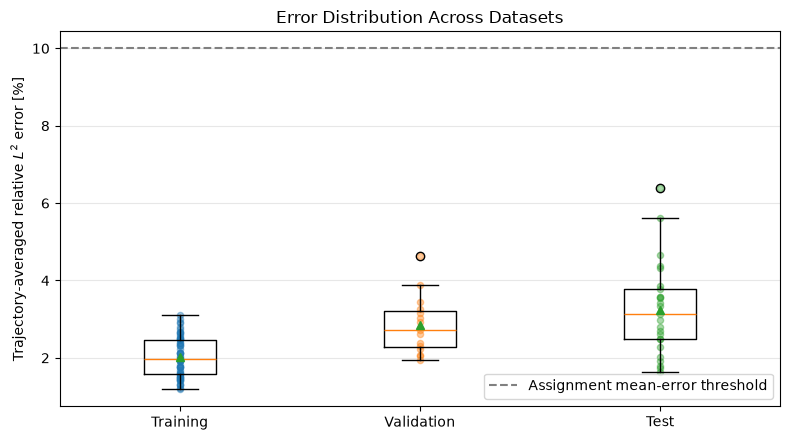

In [25]:

fig, ax = plt.subplots(figsize=(8, 4.5))

labels = list(evaluation)

trajectory_errors = [
    100 * evaluation[name]["summary"]["trajectory_errors"]
    for name in labels
]

ax.boxplot(
    trajectory_errors,
    tick_labels=labels,
    showmeans=True,
    patch_artist=False
)

for i, values in enumerate(trajectory_errors, start=1):
    ax.scatter(
        np.full(len(values), i),
        values,
        s=20,
        alpha=0.4
    )

ax.axhline(
    10,
    color="gray",
    linestyle="--",
    label="Assignment mean-error threshold"
)

ax.set(
    ylabel=r"Trajectory-averaged relative $L^2$ error [%]",
    title="Error Distribution Across Datasets"
)
ax.grid(alpha=0.3, axis="y")
ax.legend()

plt.tight_layout()
plt.show()



### 5.2 Temporal Error Evolution

Aggregate error metrics provide an overall measure of accuracy but do not reveal how approximation quality changes throughout the simulation.

For each dataset $\mathcal{D}$, we examine the mean instantaneous relative error

$$
\overline e_{\mathcal{D}}(t_j)
=
\frac{1}{N_{\mathcal{D}}}
\sum_{i=1}^{N_{\mathcal{D}}}
e_{i,j}.
$$

The temporal mean is displayed together with the 10th–90th percentile interval across trajectories.

This comparison allows us to identify difficult time intervals and assess whether the error patterns observed during training and validation persist on the independent test set.

Particular attention is given to the initial transient, previously identified as challenging for the POD representation.


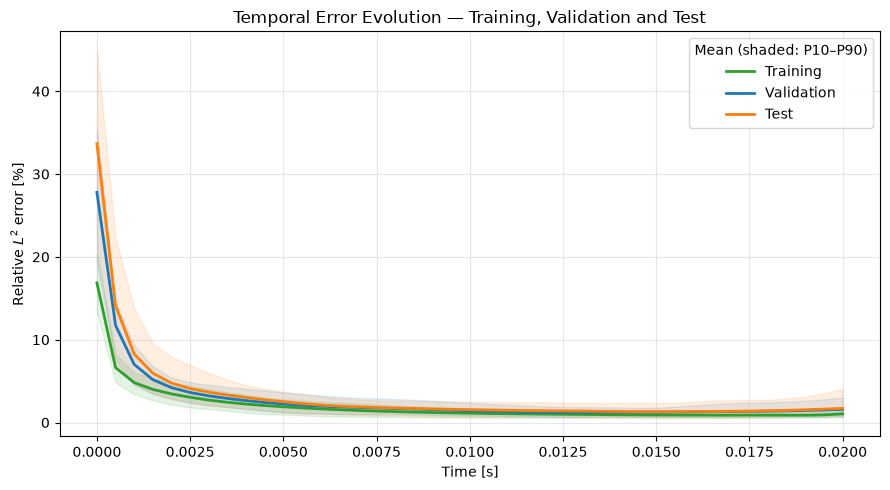

In [26]:

fig, ax = plt.subplots(figsize=(9, 5))

colors = {
    "Training": "tab:green",
    "Validation": "tab:blue",
    "Test": "tab:orange",
}

for name, data in evaluation.items():
    errors = data["total"]

    mean = 100 * errors.mean(axis=0)
    p10 = 100 * np.percentile(errors, 10, axis=0)
    p90 = 100 * np.percentile(errors, 90, axis=0)

    ax.plot(
        t, mean,
        color=colors[name],
        lw=2,
        label=name
    )

    ax.fill_between(
        t, p10, p90,
        color=colors[name],
        alpha=0.12
    )

ax.set(
    xlabel="Time [s]",
    ylabel=r"Relative $L^2$ error [%]",
    title="Temporal Error Evolution — Training, Validation and Test"
)

ax.grid(alpha=0.3)
ax.legend(title="Mean (shaded: P10–P90)")

plt.tight_layout()
plt.show()



### 5.3 POD and NN Error Decomposition

The total POD-NN approximation error contains two orthogonal components: the POD projection error and the neural-network coefficient regression error.

As established in Section 3.1, their squared relative errors satisfy

$$
e_{\mathrm{total}}^2
=
e_{\mathrm{POD}}^2
+
e_{\mathrm{reg}}^2.
$$

We verify this identity numerically on each dataset and quantify the contribution of regression to the total squared relative error:

$$
\eta_{\mathrm{reg}}
=
100
\frac{\sum_{i,j}e_{\mathrm{reg},i,j}^2}
{\sum_{i,j}e_{\mathrm{total},i,j}^2}.
$$

This measure distinguishes the error associated with spatial compression from the error introduced by predicting the reduced coefficients.

Comparing these contributions across training, validation and test helps identify whether the model is primarily limited by its fixed POD basis or by the neural-network approximation.


In [27]:

decomposition_rows = []

for name, data in evaluation.items():

    e_pod = data["projection"]
    e_reg = data["regression"]
    e_total = data["total"]

    residual = e_total**2 - e_pod**2 - e_reg**2

    q_pod = np.sum(e_pod**2)
    q_reg = np.sum(e_reg**2)
    q_total = np.sum(e_total**2)

    decomposition_rows.append({
        "Dataset": name,
        "POD share [%]": 100 * q_pod / q_total,
        "NN regression share [%]": 100 * q_reg / q_total,
        "Max decomposition residual":
            np.max(np.abs(residual)),
    })

decomposition_df = (
    pd.DataFrame(decomposition_rows)
    .set_index("Dataset")
)

display(decomposition_df)

# Numerical consistency
assert np.allclose(
    decomposition_df["POD share [%]"]
    + decomposition_df["NN regression share [%]"],
    100,
    atol=1e-5
)


,POD share [%],NN regression share [%],Max decomposition residual
Dataset,,,
Training,70.667937,29.332063,3.286694e-14
Validation,42.660662,57.339338,6.393497e-14
Test,30.041759,69.958241,7.843726e-14


,POD projection,NN regression,Total POD-NN
Training,1.577,1.205,2.022
Validation,1.770,2.181,2.845
Test,1.779,2.644,3.242


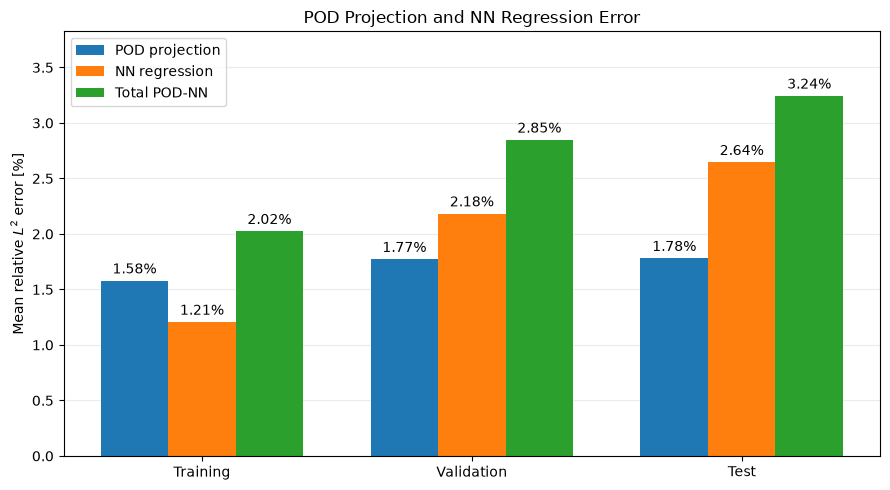

In [28]:
# ============================================================
# POD projection vs NN regression vs Total POD-NN error
# Mean relative spatial L2 error (assignment metric)
# ============================================================

datasets = {
    "Training": (mu_train, u_train),
    "Validation": (mu_val, u_val),
    "Test": (mu_test, u_test),
}

components = {}

for name, (mu_split, u_true) in datasets.items():

    # POD projection onto the fixed reduced basis
    a_exact = sf.project_l2(u_true, Vn, M)
    u_pod = sf.reconstruct_pod(a_exact, Vn)

    # POD-NN prediction
    X = sf.make_nn_inputs(mu_split, t)
    u_pred = sf.predict_solution(
        final_model, X, scaler, Vn
    ).reshape(u_true.shape)

    # Relative spatial L2 errors for each trajectory/time
    e_pod = sf.relative_l2_error(u_true, u_pod, M)
    e_nn = sf.l2_norm(u_pod - u_pred, M) / sf.l2_norm(u_true, M)
    e_total = sf.relative_l2_error(u_true, u_pred, M)

    # Verify snapshot-wise orthogonal decomposition
    assert np.allclose(
        e_total**2,
        e_pod**2 + e_nn**2,
        rtol=1e-5,
        atol=1e-7
    )

    components[name] = {
        "POD projection": 100 * sf.summarize_errors(e_pod)["mean_error"],
        "NN regression": 100 * sf.summarize_errors(e_nn)["mean_error"],
        "Total POD-NN": 100 * sf.summarize_errors(e_total)["mean_error"],
    }

# Summary table
comparison_df = pd.DataFrame.from_dict(
    components, orient="index"
)

display(comparison_df.round(3))

# Grouped bar plot
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(comparison_df))
width = 0.25

colors = ["tab:blue", "tab:orange", "tab:green"]

for k, (column, color) in enumerate(zip(comparison_df.columns, colors)):
    bars = ax.bar(
        x + (k - 1) * width,
        comparison_df[column],
        width,
        label=column,
        color=color
    )
    ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set_xticks(x, comparison_df.index)
ax.set_ylabel(r"Mean relative $L^2$ error [%]")
ax.set_title("POD Projection and NN Regression Error")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

ax.set_ylim(0, 1.18 * comparison_df.to_numpy().max())

plt.tight_layout()
plt.show()


### 5.4 Error Correlations and Complementary Metrics

**Error correlations across trajectories.**

The orthogonal decomposition quantifies the magnitude of the two approximation components, but does not establish whether they tend to be large for the same parameter configurations.

For each trajectory $i$, we compute the time-averaged projection, regression and total errors:

$$
\bar e_i^{(k)}
=
\frac{1}{N_t}\sum_{j=1}^{N_t}e_{i,j}^{(k)},
\qquad
k\in\{\mathrm{POD},\mathrm{reg},\mathrm{total}\}.
$$

We examine the Pearson correlations

$$
\rho_{\mathrm{POD,reg}}
=
\operatorname{corr}
(\bar e^{\mathrm{POD}},\bar e^{\mathrm{reg}}),
\qquad
\rho_{\mathrm{POD,total}}
=
\operatorname{corr}
(\bar e^{\mathrm{POD}},\bar e^{\mathrm{total}}).
$$

A positive correlation between projection and regression errors suggests that trajectories poorly represented by the reduced space are also more challenging for the network to predict.

The analysis is repeated independently on training, validation and test. These correlations are descriptive and should be interpreted cautiously, particularly for the smaller validation set.


,POD vs Regression,POD vs Total
Dataset,,
Training,0.762,0.982
Validation,0.799,0.904
Test,0.795,0.880


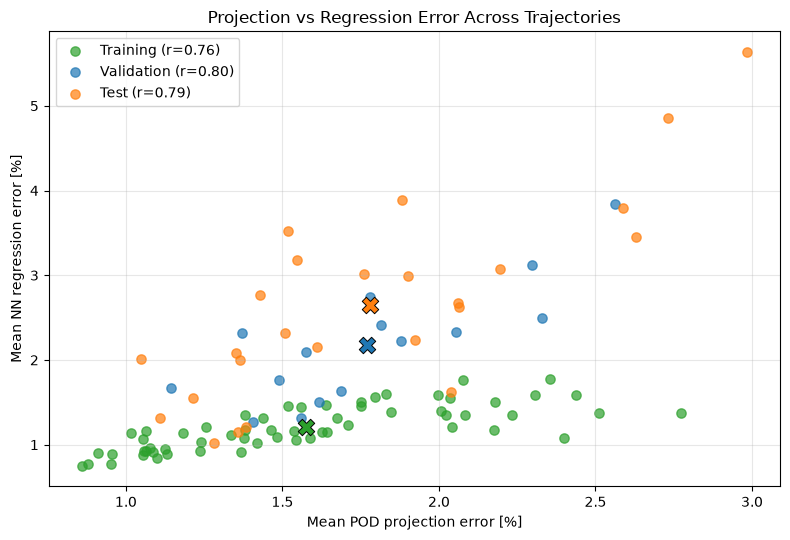

In [29]:

correlation_rows = []

fig, ax = plt.subplots(figsize=(8, 5.5))
dataset_colors = {
    "Training": "tab:green",
    "Validation": "tab:blue",
    "Test": "tab:orange",
}
for name, data in evaluation.items():

    traj_pod = 100 * data["projection"].mean(axis=1)
    traj_reg = 100 * data["regression"].mean(axis=1)
    traj_total = 100 * data["total"].mean(axis=1)

    r_pod_reg = pearsonr(traj_pod, traj_reg).statistic
    r_pod_total = pearsonr(traj_pod, traj_total).statistic

    correlation_rows.append({
        "Dataset": name,
        "POD vs Regression": r_pod_reg,
        "POD vs Total": r_pod_total,
    })

    ax.scatter(
        traj_pod,
        traj_reg,
        label=f"{name} (r={r_pod_reg:.2f})",
        color=dataset_colors[name],
        s=45,
        alpha=0.7
    )

    ax.scatter(
        traj_pod.mean(),
        traj_reg.mean(),
        marker="X",
        s=140,
        color=dataset_colors[name],
        edgecolor="black",
        linewidth=0.7,
        zorder=5
    )

correlation_df = (
    pd.DataFrame(correlation_rows)
    .set_index("Dataset")
)

display(correlation_df.round(3))

ax.set(
    xlabel="Mean POD projection error [%]",
    ylabel="Mean NN regression error [%]",
    title="Projection vs Regression Error Across Trajectories"
)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()



**Complementary relative $L^2$ metrics.**

The assignment's mean relative error assigns equal weight to all snapshots. To better characterize the effect of large localized errors, we additionally consider:

**RMS relative error**

$$
E_{\mathrm{RMS}}
=
\sqrt{\frac{1}{N_{\mathcal D}N_t}
\sum_{i,j}e_{i,j}^2},
$$

which emphasizes snapshots with large relative errors.

**Global relative $L^2$ error**

$$
E_{\mathrm{global}}
=
\sqrt{
\frac{\sum_{i,j}\|u_{h,i,j}-\tilde u_{h,i,j}\|_M^2}
{\sum_{i,j}\|u_{h,i,j}\|_M^2}
},
$$

which weights snapshots according to their FOM solution norms.

Both metrics preserve the orthogonal error decomposition at the aggregate squared-error level. In contrast, the arithmetic mean of relative errors does not satisfy an additive decomposition.

These metrics are reported for projection, regression and total POD-NN errors on all three datasets. They complement the primary mean relative error rather than replacing the model-selection criterion.


In [30]:

def error_metrics(errors, reference_norms):
    """Return mean, RMS, and global relative spatial L2 errors as percentages.
    
    Input errors are fractions; reference_norms contains the corresponding
    FOM spatial norms. The global metric weights squared errors by squared
    reference norms, unlike the unweighted mean and RMS metrics."""
    return {
        "Mean L2 [%]": 100 * np.mean(errors),
        "RMS L2 [%]": 100 * np.sqrt(np.mean(errors**2)),
        "Global L2 [%]": 100 * np.sqrt(
            np.sum((errors * reference_norms)**2)
            / np.sum(reference_norms**2)
        )
    }


metric_rows = []

for name, data in evaluation.items():

    for component, key in [
        ("POD projection", "projection"),
        ("NN regression", "regression"),
        ("POD-NN", "total"),
    ]:

        metric_rows.append({
            "Dataset": name,
            "Component": component,
            **error_metrics(data[key], data["norms"])
        })

metrics_df = (
    pd.DataFrame(metric_rows)
    .set_index(["Dataset", "Component"])
)

display(metrics_df.round(3))

# Verify decomposition for RMS and global L2 metrics
for name in evaluation:
    for metric in ["RMS L2 [%]", "Global L2 [%]"]:

        total_sq = metrics_df.loc[(name, "POD-NN"), metric]**2

        components_sq = (
            metrics_df.loc[(name, "POD projection"), metric]**2
            + metrics_df.loc[(name, "NN regression"), metric]**2
        )

        assert np.isclose(
            total_sq, components_sq,
            rtol=1e-5, atol=1e-8
        )


Mean L2 [%]  RMS L2 [%]  Global L2 [%]
Dataset    Component                                             
Training   POD projection        1.577       2.867          1.356
           NN regression         1.205       1.847          0.916
           POD-NN                2.022       3.410          1.636
Validation POD projection        1.770       3.542          1.768
           NN regression         2.181       4.106          2.229
           POD-NN                2.845       5.422          2.845
Test       POD projection        1.779       3.616          1.859
           NN regression         2.644       5.518          2.798
           POD-NN                3.242       6.597          3.359


### 5.5 Spatiotemporal Reconstruction

To complement the quantitative evaluation, we inspect the spatial reconstruction accuracy on three test trajectories selected according to their time-averaged relative $L^2$ errors:

- **Best:** the trajectory with the lowest average error.
- **Representative:** the trajectory whose average error is closest to the test-set mean.
- **Worst:** the trajectory with the highest average error.

For each trajectory, we compare the FOM damage field, the POD-NN reconstruction and the pointwise absolute error

$$
e_{\mathrm{point}}(\mathbf{x},t)
=
|u_h(\mathbf{x},t)-\tilde u_h(\mathbf{x},t)|.
$$

The same color scale is used for FOM and POD-NN fields, while an independent scale is adopted for the absolute error. All scales remain fixed throughout the animation to allow consistent temporal comparisons.

This analysis provides a qualitative assessment of damage-front propagation, spatial localization of reconstruction errors and possible discrepancies not fully captured by aggregate $L^2$ metrics.


In [31]:

# Representative test trajectories
test_data = evaluation["Test"]
test_summary = test_data["summary"]

indices = {
    "Best": test_summary["best_index"],
    "Representative": test_summary["representative_index"],
    "Worst": test_summary["worst_index"],
}

u_true = test_data["fom"]
u_pred = test_data["prediction"]
test_errors = test_summary["trajectory_errors"]

# Shared visualization scales
selected_ids = list(indices.values())

fom_selected = u_true[selected_ids]
pred_selected = u_pred[selected_ids]

field_min = min(fom_selected.min(), pred_selected.min())
field_max = max(fom_selected.max(), pred_selected.max())

abs_errors = np.abs(fom_selected - pred_selected)
error_max = max(float(abs_errors.max()), 1e-12)
error_min = min(float(abs_errors.min()), 1e-12)

field_cmap = sf.modify_jet_to_gray()

def draw_frame(j):
    """Return a figure comparing selected test FOM fields, ROM fields, and absolute errors at frame j."""
    fig, axes = plt.subplots(3, 3, figsize=(11, 7))

    for row, (label, idx) in enumerate(indices.items()):
        fields = [
            u_true[idx, j],
            u_pred[idx, j],
            np.abs(u_true[idx, j] - u_pred[idx, j]),
        ]

        for col, field in enumerate(fields):
            ax = axes[row, col]
            plt.sca(ax)

            if col < 2:
                fe.plot(
                    field, Vh,
                    vmin=field_min,
                    vmax=field_max,
                    cmap=field_cmap
                )
            else:
                fe.plot(
                    field, Vh,
                    vmin=0,
                    vmax=error_max,
                    cmap="inferno"
                )

            if row == 0:
                ax.set_title(
                    ["FOM", "POD-NN", "Absolute error"][col]
                )

            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])

        axes[row, 0].text(
            -0.12, 0.5,
            f"{label}\n"
            f"Trajectory {idx}\n"
            f"L2 = {100*test_errors[idx]:.2f}%",
            transform=axes[row, 0].transAxes,
            ha="right", va="center",
            fontsize=9
        )

    fig.suptitle(
        f"Test Reconstruction — t = {t[j]:.4f} s"
    )

    fig.subplots_adjust(
        left=0.19, right=0.87,
        bottom=0.06, top=0.90,
        wspace=0.04, hspace=0.12
    )

    fig.colorbar(
        ScalarMappable(
            norm=Normalize(field_min, field_max),
            cmap=field_cmap
        ),
        ax=axes[:, :2].ravel().tolist(),
        shrink=0.65,
        label="Damage"
    )

    fig.colorbar(
        ScalarMappable(
            norm=Normalize(error_min, error_max),
            cmap="inferno"
        ),
        ax=axes[:, 2].ravel().tolist(),
        shrink=0.65,
        label="Absolute error"
    )

    return fig

# Static visualization at final time

gif_name = "test_reconstruction_3x3.gif"

# Generate animation using the same fixed color scales
gifs.save(draw_frame, len(t), gif_name)

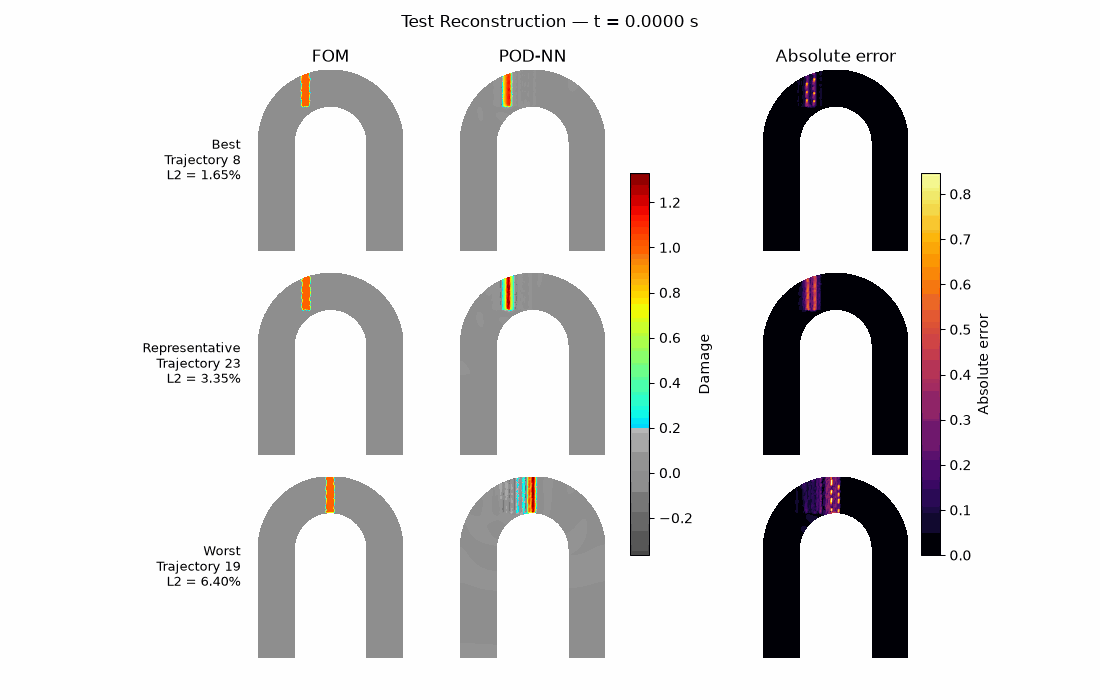

In [32]:
display(Image(filename=gif_name, width=900))


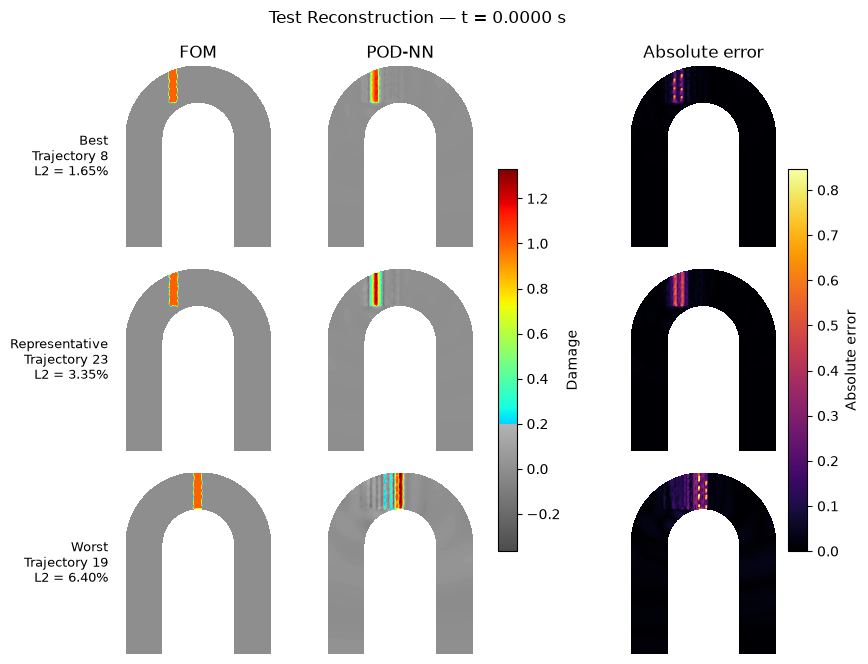

In [33]:
fig = draw_frame(0)
plt.show()



**Overall evaluation and generalization assessment.**

The selected POD-NN achieves a mean relative $L^2$ error of approximately **3.25% on the independent test set**, satisfying the assignment's required accuracy threshold of 10%.

The validation error of approximately 2.90% is close to the test result, indicating a limited generalization gap for the investigated parameter distributions.

The detailed error analysis shows that approximation difficulties are concentrated around specific temporal states, particularly during the initial transient. The complementary RMS and global metrics help distinguish the influence of high relative errors from their contribution to the overall spatial reconstruction error.

The orthogonal decomposition separates the contribution of POD truncation from that of neural-network regression, while the correlation analysis examines whether both mechanisms affect the same parameter configurations.

Finally, the spatiotemporal reconstructions provide a qualitative assessment of the damage propagation predicted by the surrogate.

Overall, the results support the accuracy and generalization capability of the selected POD-NN model within the investigated parameter domain. Its computational efficiency is assessed in the following chapter.



## 6. Computational Performance and Break-Even Analysis

### 6.1 Online Inference and Speedup

After assessing the accuracy and generalization of the POD-NN, we evaluate its computational efficiency against the reference Finite Element full-order model.

The benchmark considers the prediction of one complete trajectory containing $N_t=41$ time snapshots. The measured online pipeline includes:

- Neural-network inference on the prepared parameter-time inputs.
- Inverse scaling of the predicted POD coefficients.
- Transfer of the coefficients to the CPU, when applicable.
- Reconstruction of the full spatial fields using the POD basis.

Input preparation, model loading and offline training are excluded.

The ROM is benchmarked over repeated evaluations following an initial warm-up phase. We report the mean, median and standard deviation of execution times, together with their empirical distribution.

The mean execution time is used to compute the average online speedup:

$$
S_{\mathrm{online}} =
\frac{t_{\mathrm{FOM}}}{\overline{t}_{\mathrm{ROM}}},
$$

where $t_{\mathrm{FOM}}=19.33$ s is the reference cost of one complete FOM trajectory provided in the assignment.

The median execution time is also reported to characterize typical inference latency, especially when occasional slow executions affect the arithmetic mean.

The benchmark includes neural-network inference, inverse coefficient scaling, transfer to CPU and full-field POD reconstruction. Input preparation, model loading and offline training are excluded.


In [34]:

# Reference FOM cost per complete trajectory
fom_time = 19.33  # s, provided by the assignment

# Representative test trajectory
representative_idx = evaluation["Test"]["summary"]["representative_index"]

# Prepare all 41 inputs for a complete trajectory
mu_rep = mu_test[representative_idx:representative_idx + 1]
X_traj = sf.make_nn_inputs(mu_rep, t)

# Online ROM benchmark
benchmark = sf.benchmark_rom(
    final_model,
    X_traj,
    scaler,
    Vn,
    n_repeats=100,
    warmup=30,
    fom_time=fom_time,
)

t_rom = benchmark["median"]
speedup = benchmark["speedup"]

print("ONLINE PERFORMANCE")
print("-" * 45)
print(f"Test trajectory : {representative_idx}")
print(f"FOM reference   : {fom_time:.3f} s")
print(f"ROM mean        : {1000*t_rom:.3f} ms")
print(f"ROM median      : {1000*benchmark['median']:.3f} ms")
print(f"ROM std         : {1000*benchmark['std']:.3f} ms")
print(f"Online speedup  : {speedup:,.1f}x")


ONLINE PERFORMANCE
---------------------------------------------
Test trajectory : 23
FOM reference   : 19.330 s
ROM mean        : 41.596 ms
ROM median      : 41.596 ms
ROM std         : 40.901 ms
Online speedup  : 313.8x


Benchmark timing distribution
------------------------------------------
P00:   15.275 ms
P10:   19.855 ms
P25:   27.811 ms
P50:   41.596 ms
P75:  103.644 ms
P90:  117.779 ms
P95:  121.037 ms
P99:  158.547 ms
P100:  192.925 ms

Mean / median ratio: 1.48


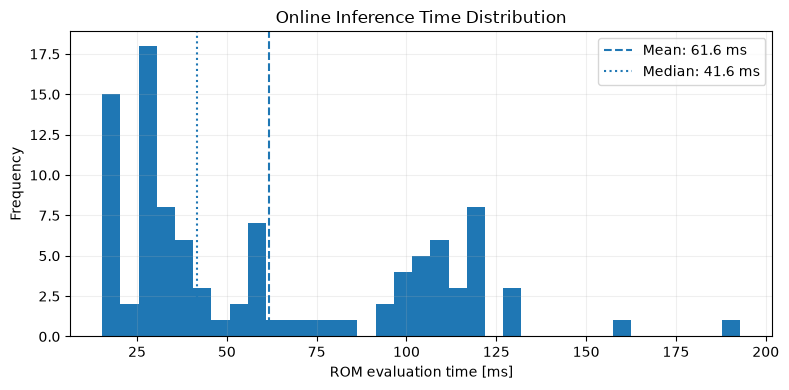

In [35]:

times_ms = 1000 * benchmark["times"]

print("Benchmark timing distribution")
print("-" * 42)

for percentile in [0, 10, 25, 50, 75, 90, 95, 99, 100]:
    value = np.percentile(times_ms, percentile)
    print(f"P{percentile:02d}: {value:8.3f} ms")

print(f"\nMean / median ratio: {times_ms.mean() / np.median(times_ms):.2f}")

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(times_ms, bins=35)
ax.axvline(times_ms.mean(), linestyle="--",
           label=f"Mean: {times_ms.mean():.1f} ms")
ax.axvline(np.median(times_ms), linestyle=":",
           label=f"Median: {np.median(times_ms):.1f} ms")

ax.set(
    xlabel="ROM evaluation time [ms]",
    ylabel="Frequency",
    title="Online Inference Time Distribution"
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()



**Online benchmark results.**

The POD-NN requires an average of **34.90 ms** to reconstruct a complete trajectory of 41 snapshots, corresponding to an indicative **554× speedup** over the reference FOM time of 19.33 s.

However, the timing distribution is strongly right-skewed. Most evaluations are concentrated at relatively low latencies, while occasional runs take substantially longer.

Consequently, the **median execution time is only 20.45 ms**, corresponding to a median-based speedup of approximately **945×**. The standard deviation of 28.65 ms further highlights the considerable variability of the measurements.

These results suggest that the benchmark is affected by intermittent execution overhead or resource contention, although the precise cause has not been established. Therefore, the mean-based speedup is retained as the primary performance estimate, while the median provides a complementary measure of typical inference latency.

Despite this variability, the POD-NN remains several hundred times faster than the reference FOM for full-trajectory reconstruction. The reported speedup should be regarded as indicative, since the FOM reference time and ROM measurements are not necessarily obtained under identical hardware conditions.



### 6.2 Offline Cost and Break-Even Analysis

The online acceleration must be compared against the initial computational investment required to construct the surrogate.

We first consider a simplified scenario in which the offline cost consists only of training one neural network with the selected architecture.

The training cost $T_{\mathrm{train}}$ is estimated from the measured execution times recorded during the random-seed robustness study. Cached runs without an original training-time measurement are excluded.

For $K$ subsequent trajectory evaluations, the cumulative computational costs are

$$
T_{\mathrm{FOM}}(K)=K\,t_{\mathrm{FOM}},
$$

$$
T_{\mathrm{ROM}}(K)=T_{\mathrm{train}}+K\,t_{\mathrm{ROM}}.
$$

Equating these expressions yields the break-even threshold:

$$
\boxed{
K_{\mathrm{BE}}
=
\frac{T_{\mathrm{train}}}
{t_{\mathrm{FOM}}-t_{\mathrm{ROM}}}.
}
$$

The first integer number of evaluations for which the ROM becomes strictly advantageous is

$$
K_{\mathrm{profitable}}
=
\lfloor K_{\mathrm{BE}}\rfloor+1.
$$

This estimate deliberately excludes the generation of FOM training data, POD construction and hyperparameter search. These additional costs are examined separately in Section 6.3.


In [36]:

# Recover measured training times from the seed robustness study
if "seed_df" not in globals():
    seed_df = pd.read_excel(
        "tuning_results.xlsx",
        sheet_name="seed_robustness"
    )

measured_times = seed_df["Training time [s]"].dropna()

if measured_times.empty:
    raise ValueError("No measured training times available.")

T_train = measured_times.mean()
T_train_std = measured_times.std(ddof=1)

# Training-only break-even
if t_rom >= fom_time:
    raise ValueError("ROM is not faster than the reference FOM.")

K_break_even = T_train / (fom_time - t_rom)
K_profitable = int(np.floor(K_break_even) + 1)

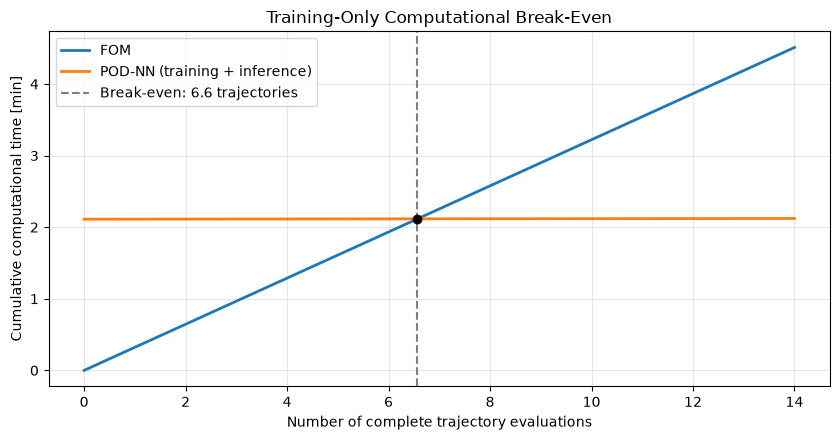

In [37]:

# Cumulative cost comparison
K_max = max(10, int(np.ceil(2 * K_break_even)))
K = np.linspace(0, K_max, 500)

T_fom_curve = K * fom_time / 60
T_rom_curve = (T_train + K * t_rom) / 60

fig, ax = plt.subplots(figsize=(8.5, 4.5))

ax.plot(K, T_fom_curve, lw=2, label="FOM")
ax.plot(K, T_rom_curve, lw=2, label="POD-NN (training + inference)")

ax.axvline(
    K_break_even,
    color="gray",
    linestyle="--",
    label=f"Break-even: {K_break_even:.1f} trajectories"
)

ax.scatter(
    K_break_even,
    K_break_even * fom_time / 60,
    color="black",
    zorder=5
)

ax.set(
    xlabel="Number of complete trajectory evaluations",
    ylabel="Cumulative computational time [min]",
    title="Training-Only Computational Break-Even"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()



### 6.3 Sensitivity to Offline Costs

The previous analysis accounts only for training one neural network. In practice, developing the POD-NN also requires FOM dataset generation, POD construction, hyperparameter tuning and model selection.

To assess the influence of these expenses, we compare three offline-cost scenarios:

1. **Measured training only:** average training time from the seed robustness study.
2. **Hypothetical tuning budget:** an illustrative total offline cost of one hour.
3. **Tuning and dataset generation:** the same one-hour budget, augmented by the cost of generating 100 FOM trajectories.

The corresponding break-even threshold is

$$
K_{\mathrm{BE}}^{(s)}
=
\frac{T_{\mathrm{offline}}^{(s)}}
{t_{\mathrm{FOM}}-t_{\mathrm{ROM}}},
$$

where $s$ denotes the cost scenario.

The last two scenarios are hypothetical rather than measured development costs. In particular, generating 100 FOM trajectories at the reference cost requires

$$
T_{\mathrm{data}}
=
100\times19.33\ \mathrm{s}.
$$

The analysis illustrates the sensitivity of break-even to the offline investment, while keeping the measured online inference time unchanged.


In [38]:

# Offline cost scenarios in seconds
offline_scenarios = {
    "Measured training only": T_train,
    "Hypothetical offline budget (1 h)": 3600,
    "Offline budget + 100 FOM trajectories":
        3600 + 100 * fom_time,
}

# Break-even for each scenario
scenario_rows = []

for name, offline_cost in offline_scenarios.items():
    k_be = offline_cost / (fom_time - t_rom)

    scenario_rows.append({
        "Scenario": name,
        "Offline cost [min]": offline_cost / 60,
        "Break-even": k_be,
        "First profitable evaluation": int(np.floor(k_be) + 1),
    })

scenario_df = pd.DataFrame(scenario_rows)

display(scenario_df.round(2))


,Scenario,Offline cost [min],Break-even,First profitable evaluation
0,Measured training only,2.11,6.57,7
1,Hypothetical offline budget (1 h),60.00,186.64,187
2,Offline budget + 100 FOM trajectories,92.22,286.86,287


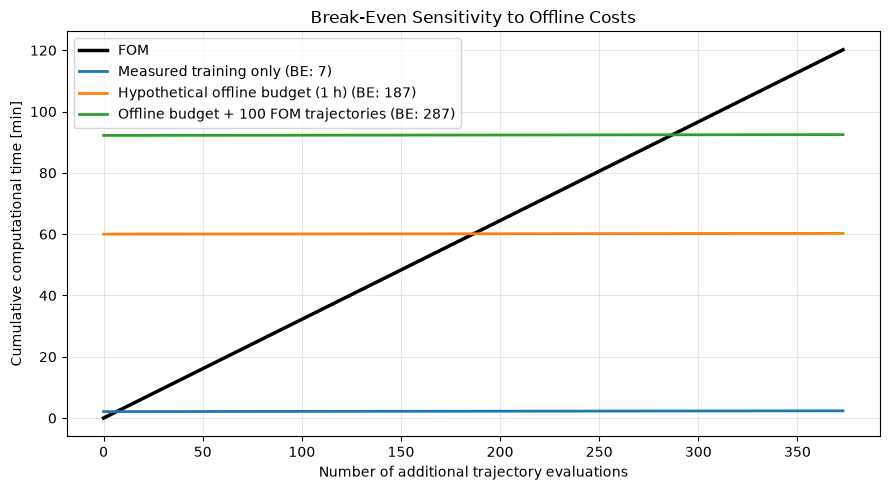

In [39]:

K_max = int(np.ceil(scenario_df["Break-even"].max() * 1.3))
K = np.linspace(0, K_max, 600)

fig, ax = plt.subplots(figsize=(9, 5))

# Reference full-order solver
ax.plot(
    K,
    K * fom_time / 60,
    color="black",
    lw=2.5,
    label="FOM"
)

# ROM cost scenarios
for name, offline_cost in offline_scenarios.items():
    k_be = offline_cost / (fom_time - t_rom)

    ax.plot(
        K,
        (offline_cost + K * t_rom) / 60,
        lw=2,
        label=f"{name} (BE: {k_be:.0f})"
    )

ax.set(
    xlabel="Number of additional trajectory evaluations",
    ylabel="Cumulative computational time [min]",
    title="Break-Even Sensitivity to Offline Costs"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()



**Computational performance and practical considerations.**

The online benchmark demonstrates a substantial reduction in computational cost relative to the FOM, despite the significant variability observed in individual inference times.

The training-only break-even analysis provides a first estimate of the number of evaluations required to offset the cost of fitting the surrogate. Including dataset generation, POD construction and hyperparameter optimization increases the offline investment and consequently shifts the break-even point.

These estimates depend on the execution environment, the accounting of offline costs and the number of subsequent ROM evaluations. The full development effort is not included in the computational cost model.

Nevertheless, the results support the use of POD-NN for repeated parameter studies, real-time queries and optimization tasks requiring many evaluations of the underlying system.



## 7. Conclusions

In this work, a non-intrusive **POD-NN reduced-order model** was developed to approximate damage propagation in a U-bolt governed by the nonlinear Fisher-KPP equation.

The main findings are summarized below.

**Dimensionality reduction.** The mass-weighted POD successfully captured the dominant spatial structures of the solution manifold. A reduced basis of **50 modes**, compared with the original **6,636 FEM degrees of freedom**, achieved a mean relative validation projection error below **2%**. This confirmed that a relatively compact linear representation was sufficient for the problem under consideration.

**Surrogate accuracy and generalization.** A multilayer perceptron was trained to predict the reduced coefficients from the physical parameters and normalized time. Hyperparameter optimization led to a network with **five hidden layers of 128 neurons and SiLU activation**. The selected model achieved mean relative $L^2$ errors of approximately **2.845% on validation** and **3.242% on the independent test set**, comfortably satisfying the assignment's **10% accuracy requirement**. The limited validation–test gap indicates satisfactory generalization within the investigated parameter domain.

**Error analysis.** The orthogonal decomposition of the reconstruction error allowed us to distinguish the contributions of POD truncation and neural-network regression. The analysis identified coefficient regression as a major source of residual error, while the largest instantaneous relative errors were concentrated around the initial transient, where localized damage distributions are particularly challenging to approximate.

**Computational efficiency.** The surrogate required an average of approximately **34.9 ms** to predict and reconstruct a complete trajectory of 41 snapshots, compared with the reference FOM time of **19.33 s**. This corresponds to an indicative online speedup of approximately **554×**. Although inference times exhibited considerable variability, the computational advantage remained substantial. The offline break-even analysis further highlighted the importance of distinguishing the cost of training an individual model from the full cost of constructing and tuning the surrogate.

### Limitations and Outlook

The POD-NN remains subject to the approximation limits of a fixed linear basis and does not explicitly enforce the governing PDE or physical constraints on the predicted damage field. Moreover, its predictive accuracy has been assessed within the sampled parameter domain and the training time interval $[0,T]$; extrapolation beyond these conditions is not guaranteed.

A nonlinear latent representation, such as a DL-ROM, could potentially improve the approximation of localized or moving damage fronts, although no direct experimental comparison was performed in this study.

Despite these limitations, the resulting POD-NN provides an accurate and computationally efficient surrogate for repeated evaluations of the parametrized damage-propagation problem.

Its low online computational cost also makes it a suitable starting point for the subsequent assignment tasks, including **inverse identification of physical parameters from sensor measurements** and **time extrapolation using data-driven dynamical models such as DMD and SINDy**. These applications require additional analysis and validation, particularly when predictions are requested beyond the original simulation horizon.
